# Is a Social Circle Also a Music Circle?
## Community Detection in the LastFM Asia Social Network
**STAT 236, Fall 2026 · Faye Fang, Grace Chen**

**Project type:** Application of existing community detection methods to real data, comparing how method choice affects the conclusions.
**Timeline 1:** Topic due October 5; report and webpage due November 8.

**Main research question:** Do users within the same communities, detected from the social network, also share their music taste?

The follow network and music taste are **two separate sources of information**:
1. **Community structure:** Using only the follow network, what communities do we find?
2. **Social circle = music circle?** Are users inside a community more similar in music taste than users in different communities?
3. **Does the method matter?** Compare Spectral, SCORE, and Louvain. Spectral versus SCORE examines degree correction; spectral methods versus Louvain examines agreement across different approaches.

The network supplies adjacency matrix A and the estimated community labels. Music supplies artist sets and Jaccard similarities; it is used only for external evaluation, never for community fitting or tuning. At the pair level the comparison concerns same/different detected-community membership and music similarity. Degree and artist counts are derived nuisance summaries, not additional research outcomes. **Country is an optional supplementary confounding check, not a primary research variable or community label.**

**Method extensions:** SCORE+ is an explicitly justified extension to the original comparison. Both its paper embedding and a truncated stabilization are retained. Detailed community profiles and illustrations use the truncated variant, without replacing the original three-method research question.

**Analysis status:** Exploratory reanalysis of an already inspected dataset, not preregistered confirmation. Network fitting and tuning use only the graph. Main inference uses the degree/activity permutation reference. Pair weighting, SCORE+ implementations, and country references are supporting analyses with clearly identified roles.

**Notebook route:** §1 data; §2 network models and algorithms; §3 music similarity; §4 main community/music test; §5 original-method comparisons; §6 sensitivity; §7 network illustrations; §8 reproducibility and findings. Appendix A contains recovery simulations; Appendix B contains supplementary country checks and diagnostics; Appendix C contains core-method visualizations; Appendix D contains primary calibration, matched-information recovery and shared perturbations; Appendix E collects report evidence.

**Course emphasis:** sparse-network signal and noise, SBM/DCBM, degree heterogeneity, eigenvector localization, regularization, dependent dyads, exchangeability and simulation-based evaluation. Earlier course-slide numbers have not been independently verified.


## 0. Setup

In [1]:
import os, json, time, random, platform, hashlib, importlib.metadata
from pathlib import Path
import sys
START_DIR = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [START_DIR, *START_DIR.parents]
                     if (p / 'data').is_dir() and (p / 'code/lastfm_stats.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook within the project directory or code/ folder.')
sys.path.insert(0, str(PROJECT_ROOT / 'code'))
from datetime import datetime, timezone
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from scipy.stats import t as student_t
import lastfm_stats as stats
import numpy as np
import pandas as pd
import networkx as nx
import scipy
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI
import matplotlib as mpl
import matplotlib.pyplot as plt
import igraph as ig

threadpool_limits(limits=4)
RUN_STARTED = datetime.now(timezone.utc).isoformat()
PROFILE = os.environ.get("STAT236_PROFILE", "full")
assert PROFILE in {"full", "smoke"}

# ---- configuration -------------------------------------------------------
SEED = 236                 # global seed; every random step derives from it
DATA_DIR = str(PROJECT_ROOT / 'data')
RUN_ROOT = PROJECT_ROOT / 'tmp/smoke' if PROFILE == 'smoke' else PROJECT_ROOT
FIG_DIR, TAB_DIR, OUT_DIR = [str(RUN_ROOT / d) for d in ('figures', 'tables', 'outputs')]
for d in (FIG_DIR, TAB_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

B_MAIN   = 1999   # permutations for each main reference
B_ROBUST = 199    # permutations for exploratory sensitivity checks
N_SUB    = 10     # edge-subsamples for K-selection stability
N_SIM    = 20     # replications per DCBM simulation setting
N_INIT   = 20     # k-means random starts
K_RANGE  = range(3, 21)
if PROFILE == "smoke":
    B_MAIN, B_ROBUST, N_SUB, N_SIM = 9, 5, 2, 1
B_COUNTRY = B_ROBUST  # supplementary country references; primary test retains B_MAIN
CORE_METHODS = ['Spectral', 'SCORE', 'Louvain']
PRIMARY_REFERENCE = 'degree_activity_q5'
DETAIL_METHOD = "SCORE+ (truncated)"
PAPER_METHOD = "SCORE+ (paper)"

# ---- plotting style (consistent colors per method across all figures) ----
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
METHOD_ORDER = ['Spectral', 'SCORE', PAPER_METHOD, DETAIL_METHOD, 'Louvain']
METHOD_COLOR = {PAPER_METHOD: '#6250d6', DETAIL_METHOD: '#2a78d6', 'Louvain': '#eb6834', 'SCORE': '#1baf7a', 'Spectral': '#eda100'}
CAT8 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
OTHER = '#b9b8b2'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'lines.linewidth': 2,
})
def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'))
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'))
def savetab(df, name, index=False):
    df.to_csv(os.path.join(TAB_DIR, name + '.csv'), index=index, float_format='%.12g')

print('Python', platform.python_version(), '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| scikit-learn', sklearn.__version__, '| igraph', ig.__version__)
print("Profile:", PROFILE, "| main permutations:", B_MAIN, "| sensitivity permutations:", B_ROBUST)

Python 3.12.3 | numpy 2.5.4 | scipy 1.18.1 | networkx 3.7 | scikit-learn 1.9.1 | igraph 1.0.0
Profile: full | main permutations: 1999 | sensitivity permutations: 199


## 1. Data and preprocessing

**Source.** LastFM Asia Social Network (Rozemberczki & Sarkar, 2020), SNAP: https://snap.stanford.edu/data/feather-lastfm-social.html. Users are nodes, mutual follows are undirected edges, and each user has a list of liked artists (anonymous integer IDs). The file also contains each user's **country** (anonymous code, 18 classes); we use it only in Appendix B as a supplementary potential-confounder check.

The loader accepts either the original SNAP files (`lastfm_asia_edges.csv`, `lastfm_asia_features.json`, `lastfm_asia_target.csv`) or the identical dataset as distributed in the authors' `karateclub` repository (`lastfm_edges.csv`, `lastfm_features.csv`, `lastfm_target.csv`). Put the files in `data/`.

**Preprocessing (as in the proposal).** Check duplicate edges and self-loops; keep users who have music data; keep the largest connected component (LCC) of the network induced on them. The LCC is required by SCORE-type methods, whose leading eigenvector must be strictly positive.

In [2]:
def load_lastfm(data_dir=DATA_DIR):
    p = lambda f: os.path.join(data_dir, f)
    if os.path.exists(p('lastfm_asia_edges.csv')):                     # SNAP version
        edges = pd.read_csv(p('lastfm_asia_edges.csv'))
        target = pd.read_csv(p('lastfm_asia_target.csv'))
        with open(p('lastfm_asia_features.json')) as fh:
            feats = json.load(fh)
        rows = [(int(u), a) for u, arts in feats.items() for a in arts]
        likes = pd.DataFrame(rows, columns=['node_id', 'artist_id'])
        src = 'SNAP'
    else:                                                               # karateclub version
        edges = pd.read_csv(p('lastfm_edges.csv'))
        target = pd.read_csv(p('lastfm_target.csv'))
        fpath = p('lastfm_features.csv') if os.path.exists(p('lastfm_features.csv')) else p('lastfm_features.csv.gz')
        likes = pd.read_csv(fpath).rename(columns={'feature_id': 'artist_id'})[['node_id', 'artist_id']]
        src = 'karateclub'
    edges.columns = ['u', 'v']
    target.columns = ['node_id', 'country']
    return edges, likes, target, src

edges_raw, likes_raw, target, SRC = load_lastfm()
print(f'source: {SRC} | edge rows: {len(edges_raw):,} | like rows: {len(likes_raw):,} | users with country: {len(target):,}')

source: karateclub | edge rows: 27,806 | like rows: 3,014,361 | users with country: 7,624


In [3]:
# --- integrity checks -----------------------------------------------------
n_self = int((edges_raw.u == edges_raw.v).sum())
canon = np.sort(edges_raw[['u', 'v']].values, axis=1)
n_dup = int(pd.DataFrame(canon).duplicated().sum())
n_dup_likes = int(likes_raw.duplicated().sum())

G_full = nx.Graph()
G_full.add_nodes_from(target.node_id)
G_full.add_edges_from(canon[canon[:, 0] != canon[:, 1]])
music_users = set(likes_raw.node_id.unique())

G_music = G_full.subgraph([v for v in G_full if v in music_users])
lcc = max(nx.connected_components(G_music), key=len)
G = G_music.subgraph(lcc).copy()

nodes = np.array(sorted(G.nodes()))
n = len(nodes)
idx = {v: i for i, v in enumerate(nodes)}
A = nx.to_scipy_sparse_array(G, nodelist=nodes, format='csr').astype(np.float64)
deg = np.asarray(A.sum(1)).ravel()
country = target.set_index('node_id').loc[nodes, 'country'].values

# user x artist incidence matrix
lk = likes_raw.drop_duplicates()
lk = lk[lk.node_id.isin(idx)]
X = sp.csr_matrix((np.ones(len(lk), dtype=np.float32), (lk.node_id.map(idx).values, lk.artist_id.values)),
                  shape=(n, int(likes_raw.artist_id.max()) + 1))
X = X[:, np.asarray(X.sum(0)).ravel() > 0].tocsr()      # drop artists nobody in the sample likes
n_art = np.asarray(X.sum(1)).ravel()
art_pop = np.asarray(X.sum(0)).ravel()

summary = pd.DataFrame([
    ('Users (raw)', G_full.number_of_nodes()),
    ('Mutual-follow edges (raw)', len(edges_raw)),
    ('Self-loops', n_self),
    ('Duplicate edges', n_dup),
    ('Connected components (raw graph)', nx.number_connected_components(G_full)),
    ('Users without music data', G_full.number_of_nodes() - len(music_users & set(G_full))),
    ('Components after dropping them', nx.number_connected_components(G_music)),
    ('Users in final sample (LCC)', n),
    ('Edges in final sample', G.number_of_edges()),
    ('Distinct artists in final sample', X.shape[1]),
    ('Mean degree', round(deg.mean(), 2)),
    ('Median degree', np.median(deg)),
    ('Max degree', int(deg.max())),
    ('Mean #artists per user', round(float(n_art.mean()), 1)),
    ('Median #artists per user', np.median(n_art)),
    ('Min #users per artist', int(art_pop.min())),
    ('Countries', len(np.unique(country))),
], columns=['Quantity', 'Value'])
summary['Value'] = [f'{v:,.0f}' if float(v).is_integer() else f'{v:,.1f}' for v in summary.Value.astype(float)]
savetab(summary, 'tab01_data_summary')
summary

# Fail early on alignment or incidence errors instead of producing plausible output.
assert target.node_id.is_unique
assert set(edges_raw.u) | set(edges_raw.v) <= set(target.node_id)
assert set(likes_raw.node_id) <= set(target.node_id)
assert nx.is_connected(G) and np.all(deg > 0)
assert A.shape == (n, n) and (A != A.T).nnz == 0 and np.all(A.diagonal() == 0)
assert np.all(X.data == 1) and np.all(n_art > 0)
assert np.array_equal(nodes, np.sort(nodes))

inclusion = target[['node_id', 'country']].copy()
inclusion['has_music'] = inclusion.node_id.isin(music_users)
inclusion['in_lcc_analysis'] = inclusion.node_id.isin(nodes)
inclusion['raw_degree'] = inclusion.node_id.map(dict(G_full.degree()))
attrition = inclusion.groupby('country').agg(raw_users=('node_id', 'size'), music_users=('has_music', 'sum'),
    analysis_users=('in_lcc_analysis', 'sum'), mean_raw_degree=('raw_degree', 'mean'))
attrition['retention_fraction'] = attrition.analysis_users / attrition.raw_users
savetab(attrition, 'tab14_attrition_by_country', index=True)

**Sampling population.** The analysis concerns the largest connected component among observed users with at least one recorded artist. The retention table (`tab14_attrition_by_country.csv`) documents exclusions by country. Missing music need not be missing at random, and excluded users cannot be represented by an unqualified population claim. Artist IDs and country labels are anonymous; recorded likes are not listening histories.

Spearman correlation between degree and #artists: 0.246
Degree quantiles (50/90/99/max): [ 4.  16.  54.7] 214


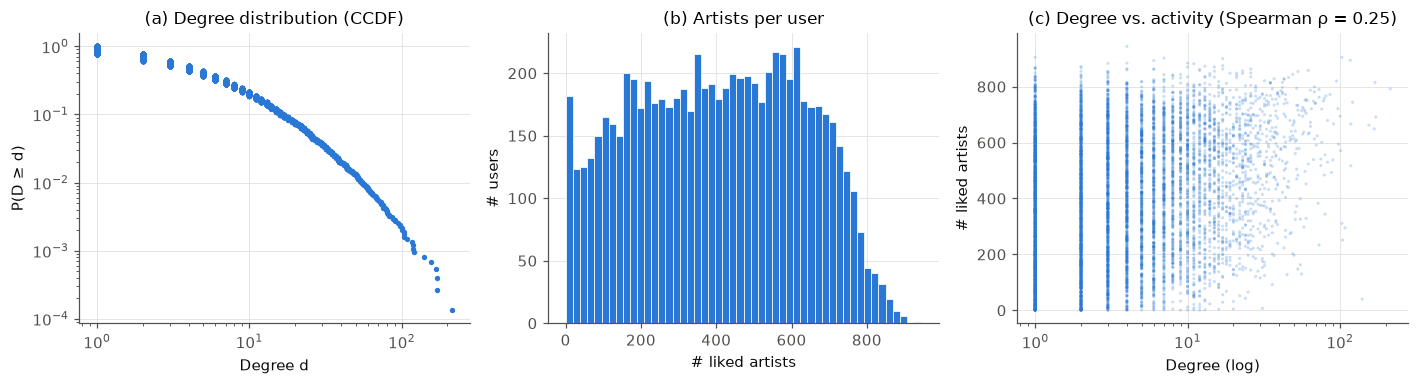

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) degree distribution (log-log CCDF)
ds = np.sort(deg)
ccdf = 1 - np.arange(n) / n
ax[0].loglog(ds, ccdf, color=METHOD_COLOR[DETAIL_METHOD], marker='o', ms=2.5, lw=0)
ax[0].set(xlabel='Degree d', ylabel='P(D ≥ d)', title='(a) Degree distribution (CCDF)')
# (b) number of artists per user
ax[1].hist(n_art, bins=50, color=METHOD_COLOR[DETAIL_METHOD], edgecolor='white', linewidth=0.5)
ax[1].set(xlabel='# liked artists', ylabel='# users', title='(b) Artists per user')
# (c) degree vs #artists
ax[2].scatter(deg, n_art, s=4, alpha=0.25, color=METHOD_COLOR[DETAIL_METHOD], edgecolor='none')
ax[2].set_xscale('log')
rho = pd.Series(deg).corr(pd.Series(n_art), method='spearman')
ax[2].set(xlabel='Degree (log)', ylabel='# liked artists', title=f'(c) Degree vs. activity (Spearman ρ = {rho:.2f})')
fig.tight_layout(); savefig(fig, 'fig01_degree_artists'); plt.show()
print(f'Spearman correlation between degree and #artists: {rho:.3f}')
print('Degree quantiles (50/90/99/max):', np.quantile(deg, [.5, .9, .99]).round(1), int(deg.max()))

**EDA interpretation.** Degree heterogeneity and sparsity motivate a degree-corrected network model. A roughly linear log-log tail is descriptive evidence, not a fitted or validated power law. The degree/activity association motivates nuisance adjustment, but coarse stratification will not remove all continuous-covariate differences.

## 2. Network model and community detection: original comparison and extensions

For $i<j$, the Bernoulli DCBM assumes conditionally independent edges with
$$A_{ij}\mid(c,\theta,B)\sim\operatorname{Bernoulli}(\theta_i\theta_j B_{c_i c_j}),\quad A_{ii}=0.$$
The symmetric nonnegative $B$ and degree propensities $\theta_i>0$ need a scaling constraint (e.g. $\sum_{i:c_i=k}\theta_i=1$ per block); probabilities must be at most one. Up to removal of its diagonal, the signal $\Omega=\Theta ZBZ^\top\Theta$ has rank at most $K$. SBM suppresses within-block degree heterogeneity. In the population idealization, eigenvector rows are scaled by $\theta_i$; taking ratios cancels this nuisance scale. Sparse noise and tiny denominators can disrupt the empirical cancellation.

We do not assume that this real social network exactly follows a DCBM. Hard nonoverlapping communities, conditional edge independence, and model fit are limitations. Simulation tests algorithm behavior under specified generators, not the truth of the real partition.

**Core comparison:** Spectral, SCORE and Louvain answer the original method-choice question. SCORE+ implementations are additional comparisons motivated by the network diagnostics. **All algorithms fit without music or country:**
- **Spectral:** top-$K$ adjacency eigenvectors, then k-means; an explicitly unnormalized baseline.
- **SCORE:** adjacency eigenvector ratios, truncated at $\pm\log n$, then k-means.
- **SCORE+ (paper):** $L_\tau=(D+\tau I)^{-1/2}A(D+\tau I)^{-1/2}$, optional extra eigenvector, eigenvalue-weighted ratios, then k-means **without truncation**.
- **SCORE+ (truncated):** same embedding with ratios clipped at $\pm\log n$ before k-means. This is an explicit stabilization of the paper algorithm, used for detailed illustrations as an extension of the original three-method comparison. Its benefits and costs must be assessed separately.
- **Louvain:** modularity optimization with resolution chosen to approximate the graph-selected $K$.

We use $\tau=\bar d$ and assess the published $0.1d_{\max}$ setting separately. Eigenpairs are ordered by magnitude; the extra-vector rule uses $1-\hat\lambda_{K+1}/\hat\lambda_K\le0.1$. The extra-vector rule uses signed eigenvalues as in the paper; graph-only K selection separately uses a magnitude gap. No claim of a weak-signal theorem follows merely from an empirical small eigengap. See [Jin, Ke & Luo, §3.1](https://arxiv.org/pdf/1811.05927) for the algorithm definition.

In [5]:
leading_eigs = stats.leading_eigs
reg_laplacian = stats.reg_laplacian
relabel_by_size = stats.relabel_by_size
score_ratios = stats.score_ratios
scoreplus_M = stats.scoreplus_M

def kmeans(Y, K, seed=SEED):
    return stats.kmeans(Y, K, seed=seed, n_init=N_INIT)

def spectral_labels(vecs, K, seed=SEED):
    return kmeans(vecs[:, :K], K, seed)

def score_labels(vecs, K, seed=SEED):
    return kmeans(score_ratios(vecs, K), K, seed)

def scoreplus_labels(vals, vecs, K, t=0.1, seed=SEED, truncate=True):
    return stats.scoreplus_labels(vals, vecs, K, t=t, seed=seed, truncate=truncate, n_init=N_INIT)

def louvain_labels(Gx, resolution, seed=SEED, nodelist=None):
    comms = nx.community.louvain_communities(Gx, resolution=resolution, seed=seed)
    nl = nodes if nodelist is None else nodelist
    pos = {v: i for i, v in enumerate(nl)}
    lab = np.empty(len(nl), dtype=int)
    for k, community in enumerate(comms):
        lab[[pos[v] for v in community]] = k
    return relabel_by_size(lab)

### 2.1 Localization and numerical diagnostics
Compare mass in the 50 largest coordinates and $n\sum_i\hat\xi_j(i)^4$ (equal-magnitude coordinates give 1). Large ratios and frequent clipping diagnose embedding sensitivity. Positive power iteration refines the leading denominator entrywise; the numerical residual and all eigenvalues are saved. Localization is an observed diagnosis, not proof that a theorem's assumptions fail.

In [6]:
vals_A, vecs_A = leading_eigs(A, 30)
TAU = deg.mean()                                  # Lec9 slide 28: H = D + d_bar I
L = reg_laplacian(A, TAU)
vals_L, vecs_L = leading_eigs(L, 30)

def loc_stats(vecs, K=11):
    top50 = np.array([np.sort(vecs[:, k] ** 2)[::-1][:50].sum() for k in range(3)])
    ipr = np.array([n * (vecs[:, k] ** 4).sum() for k in range(3)])
    with np.errstate(divide='ignore', invalid='ignore'):
        R = vecs[:, 1:K] / vecs[:, [0]]
    clipped = np.mean(~(np.abs(R) <= np.log(n)))
    return top50, ipr, clipped

rows = []
for name, M_ in [('A (adjacency)', None), ('L_τ, τ = d̄ (Lec9 slide 28)', TAU)]:
    v = vecs_A if M_ is None else vecs_L
    top50, ipr, cl = loc_stats(v)
    rows.append({'Matrix': name, 'Top-50 mass ξ1': top50[0], 'Top-50 mass ξ2': top50[1], 'Top-50 mass ξ3': top50[2],
                 'n·IPR ξ1': ipr[0], 'n·IPR ξ2': ipr[1], '% SCORE ratios truncated (K=11)': 100 * cl})
# regularization used by the published SCORE+ default: tau = 0.1 * d_max
_, v_dmax = leading_eigs(reg_laplacian(A, 0.1 * deg.max()), 30)
top50, ipr, cl = loc_stats(v_dmax)
rows.append({'Matrix': f'L_τ, τ = 0.1·d_max = {0.1*deg.max():.1f} (SCORE+ default, Lec9 slide 43)', 'Top-50 mass ξ1': top50[0],
             'Top-50 mass ξ2': top50[1], 'Top-50 mass ξ3': top50[2], 'n·IPR ξ1': ipr[0], 'n·IPR ξ2': ipr[1],
             '% SCORE ratios truncated (K=11)': 100 * cl})
loc_tab = pd.DataFrame(rows).round(3)
savetab(loc_tab, 'tab02_localization')
loc_tab

eigen_diagnostics = []
for name, matrix, values, vectors in [('A', A, vals_A, vecs_A), ('L_tau', L, vals_L, vecs_L)]:
    for j, value in enumerate(values):
        residual = np.linalg.norm(matrix @ vectors[:, j] - value * vectors[:, j]) / max(abs(value), 1e-15)
        eigen_diagnostics.append(dict(matrix=name, rank=j + 1, eigenvalue=value, relative_residual=residual,
                                      minimum_abs_coordinate=np.abs(vectors[:, j]).min()))
savetab(pd.DataFrame(eigen_diagnostics), 'tab15_eigen_diagnostics')
assert np.all(vecs_A[:, 0] > 0) and np.all(vecs_L[:, 0] > 0)
assert max(row['relative_residual'] for row in eigen_diagnostics) < 1e-7

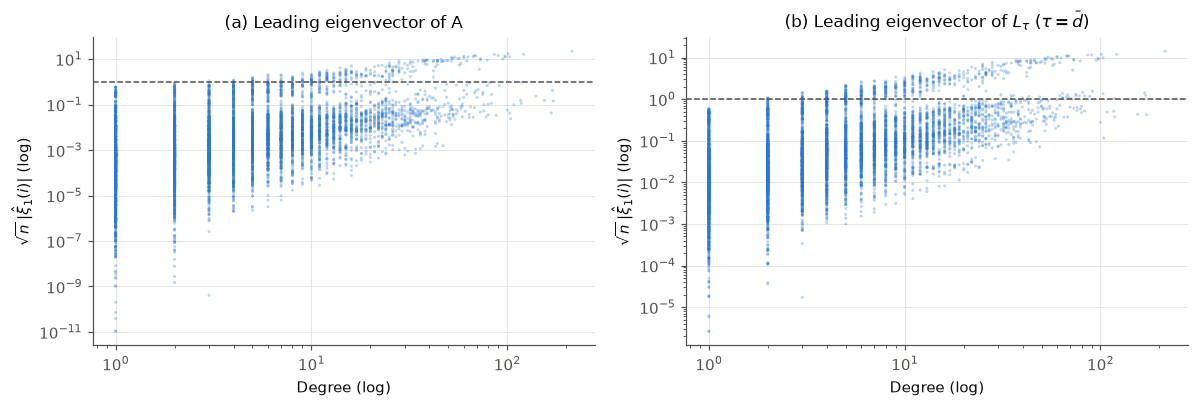

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for a, v, ttl in [(ax[0], vecs_A[:, 0], '(a) Leading eigenvector of A'),
                  (ax[1], vecs_L[:, 0], '(b) Leading eigenvector of $L_\\tau$ ($\\tau=\\bar d$)')]:
    a.scatter(deg, np.abs(v) * np.sqrt(n), s=4, alpha=0.3, color=METHOD_COLOR[DETAIL_METHOD], edgecolor='none')
    a.set_xscale('log'); a.set_yscale('log')
    a.axhline(1, color=INK2, lw=1, ls='--')
    a.set(xlabel='Degree (log)', ylabel='$\\sqrt{n}\\,|\\hat\\xi_1(i)|$ (log)', title=ttl)
fig.tight_layout(); savefig(fig, 'fig02_localization'); plt.show()

**Interpretation rule.** Use the computed localization table to compare adjacency and regularized embeddings. Do not equate the fraction of clipped unweighted SCORE ratios with the fraction of clipped eigenvalue-weighted SCORE+ ratios; the latter is reported separately in Appendix B. Neither a lower localization metric nor a higher music lift establishes that a partition is the true one.

### 2.2 Choosing $K$ from the graph
The selection rule is the largest **unrounded** relative eigengap of $L_\tau$ over $K=3,\ldots,20$. Community sizes and stability under independent 10% edge deletions are diagnostics, not additional undisclosed selection rules. For each perturbation, fit the induced largest connected component and compare to the original labels on the retained vertices. Error bars below are SD across graph perturbations, not confidence intervals for the true number of communities. All music similarities and country labels are excluded from tuning.

In [8]:
rng = np.random.default_rng(SEED)
iu_edges = np.array(sp.triu(A).nonzero()).T
subsamples = []
for r in range(N_SUB):
    keep = iu_edges[rng.random(len(iu_edges)) < 0.9]
    Bm = sp.coo_matrix((np.ones(len(keep)), (keep[:, 0], keep[:, 1])), shape=(n, n))
    Bm = (Bm + Bm.T).tocsr()
    ncomp, comp = sp.csgraph.connected_components(Bm, directed=False)
    cc = np.where(comp == np.bincount(comp).argmax())[0]
    Bs = Bm[cc][:, cc]
    subsamples.append((cc, leading_eigs(reg_laplacian(Bs, Bs.sum() / len(cc)), 25)))

k_rows = []
for K in K_RANGE:
    lab = scoreplus_labels(vals_L, vecs_L, K)
    stab = [NMI(lab[cc], scoreplus_labels(bv, BV, K)) for cc, (bv, BV) in subsamples]
    sizes = np.bincount(lab)
    k_rows.append({'K': K, 'rel_eigengap': 1 - abs(vals_L[K]) / abs(vals_L[K - 1]), 'M (SCORE+)': scoreplus_M(vals_L, K),
                   'stability_NMI': np.mean(stab), 'stability_sd': np.std(stab, ddof=1),
                   'largest': sizes.max(), 'smallest': sizes.min()})
k_tab = pd.DataFrame(k_rows)
savetab(k_tab, 'tab03_K_selection')
k_tab

Out[8]: 
     K  rel_eigengap  M (SCORE+)  ...  stability_sd  largest  smallest
0    3      0.015378           4  ...      0.148920     4541      1193
1    4      0.005778           5  ...      0.082461     3829       670
2    5      0.006943           6  ...      0.069031     4014       332
3    6      0.027892           7  ...      0.024471     2157       327
4    7      0.018642           8  ...      0.042344     2151       140
5    8      0.003238           9  ...      0.044310     2124       138
6    9      0.006884          10  ...      0.015288     1885       138
7   10      0.029639          11  ...      0.017754     1907       138
8   11      0.057666          12  ...      0.029361     1892       138
9   12      0.017561          13  ...      0.039713     1466       127
10  13      0.009353          14  ...      0.028184     1481       127
11  14      0.003766          15  ...      0.022879     1473       126
12  15      0.010218          16  ...      0.013214     1445       1

K chosen by largest relative eigengap in 3..20: 11


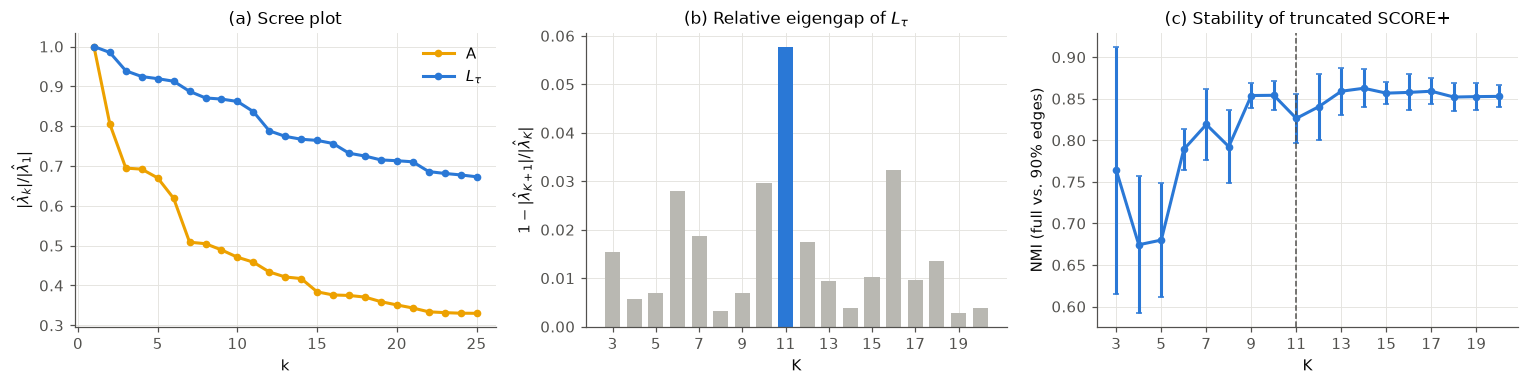

In [9]:
K_STAR = int(k_tab.loc[k_tab.rel_eigengap.idxmax(), 'K'])
print('K chosen by largest relative eigengap in 3..20:', K_STAR)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
kk = np.arange(1, 26)
ax[0].plot(kk, np.abs(vals_A[:25]) / np.abs(vals_A[0]), marker='o', ms=4, color=METHOD_COLOR['Spectral'], label='A')
ax[0].plot(kk, np.abs(vals_L[:25]) / np.abs(vals_L[0]), marker='o', ms=4, color=METHOD_COLOR[DETAIL_METHOD], label='$L_\\tau$')
ax[0].set(xlabel='k', ylabel='$|\\hat\\lambda_k| / |\\hat\\lambda_1|$', title='(a) Scree plot')
ax[0].legend()
bars = ax[1].bar(k_tab.K, k_tab.rel_eigengap, color=[METHOD_COLOR[DETAIL_METHOD] if k == K_STAR else OTHER for k in k_tab.K], width=0.7)
ax[1].set(xlabel='K', ylabel='$1-|\\hat\\lambda_{K+1}|/|\\hat\\lambda_K|$', title='(b) Relative eigengap of $L_\\tau$')
ax[2].errorbar(k_tab.K, k_tab.stability_NMI, yerr=k_tab.stability_sd, color=METHOD_COLOR[DETAIL_METHOD], marker='o', ms=4, capsize=2)
ax[2].axvline(K_STAR, color=INK2, ls='--', lw=1)
ax[2].set(xlabel='K', ylabel='NMI (full vs. 90% edges)', title='(c) Stability of truncated SCORE+')
for a in ax[1:]:
    a.set_xticks(list(range(3, 21, 2)))
fig.tight_layout(); savefig(fig, 'fig03_K_selection'); plt.show()

**Interpretation rule.** Report the selected gap, community sizes, and perturbation NMI from the tables. Eigengap selection is a heuristic; it does not prove that the graph contains exactly this many communities. Sensitivity across several $K$ values is required. The extra-vector decision concerns the embedding dimension, not a test of signal strength.

### 2.3 Louvain resolution

Louvain picks its own number of communities. We first record what the **default** $\gamma=1$ gives, then scan $\gamma$ and choose the value whose median number of communities (over 5 seeds) is closest to $K^*$, so all methods are compared at a similar granularity. Stability across seeds is measured by the mean pairwise NMI of 10 runs.

In [10]:
gam_rows = []
for gam in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0]:
    labs = [louvain_labels(G, gam, seed=SEED + s) for s in range(5)]
    Ks = [l.max() + 1 for l in labs]
    Qs = [nx.community.modularity(G, [set(nodes[l == k]) for k in range(l.max() + 1)]) for l in labs]
    gam_rows.append({'gamma': gam, 'K_median': np.median(Ks), 'K_min': min(Ks), 'K_max': max(Ks), 'modularity(γ=1)': np.mean(Qs)})
gam_tab = pd.DataFrame(gam_rows)
GAMMA = float(gam_tab.loc[(gam_tab.K_median - K_STAR).abs().idxmin(), 'gamma'])
savetab(gam_tab, 'tab04_louvain_resolution')
print('Chosen resolution γ =', GAMMA)
gam_tab

Chosen resolution γ = 0.25
Out[10]: 
   gamma  K_median  K_min  K_max  modularity(γ=1)
0   0.05       3.0      3      3         0.436179
1   0.10       7.0      7      8         0.745068
2   0.15       8.0      8      8         0.766042
3   0.20       8.0      8      9         0.773703
4   0.25      11.0     10     11         0.791653
5   0.30      12.0     11     12         0.805081
6   0.40      13.0     12     15         0.809782
7   0.50      14.0     13     15         0.812040
8   0.70      17.0     16     19         0.813845
9   1.00      28.0     26     30         0.815957


In [11]:
louv_runs = [louvain_labels(G, GAMMA, seed=SEED + s) for s in range(10)]
pair_nmi = [NMI(louv_runs[i], louv_runs[j]) for i in range(10) for j in range(i + 1, 10)]
print(f'Louvain (γ={GAMMA}) across 10 seeds: K = {sorted(set(l.max()+1 for l in louv_runs))}, '
      f'mean pairwise NMI = {np.mean(pair_nmi):.3f} (min {np.min(pair_nmi):.3f})')
louv_default = louvain_labels(G, 1.0)
print(f'Louvain default γ=1: K = {louv_default.max()+1}')

Louvain (γ=0.25) across 10 seeds: K = [np.int64(10), np.int64(11)], mean pairwise NMI = 0.925 (min 0.889)
Louvain default γ=1: K = 28


**Comparison caveat.** Louvain is not constrained to produce exactly $K$ groups. We choose its resolution using only the median group count over five seeds, then use the prespecified seed 236 for the analysis, rather than selecting a seed with a favorable music effect. Modularity values above are evaluated at resolution 1 for comparability; they are not likelihoods or proofs of recovery.

### 2.4 Final partitions

community (by size),0,1,2,3,4,5,6,7,8,9,10
Spectral,6830,99,71,70,66,65,55,53,44,43,35
SCORE+ (paper),4651,1297,1087,124,71,56,47,43,28,21,6
SCORE,1391,1160,921,777,607,581,507,444,415,365,263
SCORE+ (truncated),1892,1261,1009,946,645,555,325,304,212,144,138
Louvain,1766,1574,1096,998,596,575,480,172,99,62,13


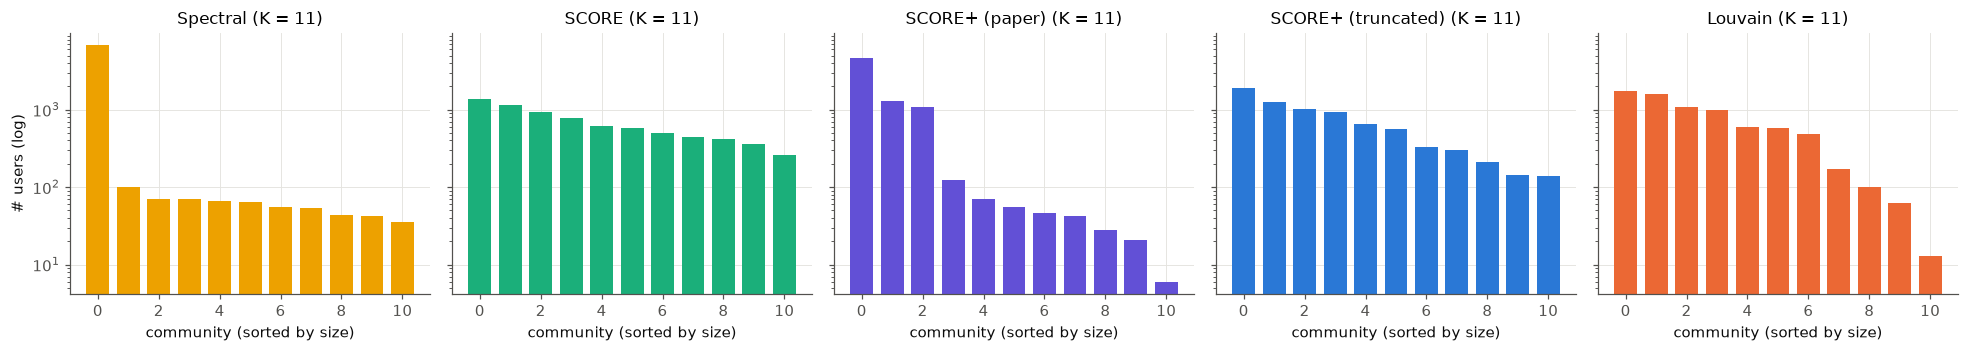

In [12]:
partitions = {
    'Spectral': spectral_labels(vecs_A, K_STAR),
    PAPER_METHOD: scoreplus_labels(vals_L, vecs_L, K_STAR, truncate=False),
    'SCORE':    score_labels(vecs_A, K_STAR),
    DETAIL_METHOD:   scoreplus_labels(vals_L, vecs_L, K_STAR),
    'Louvain':  louv_runs[0],
}
pd.DataFrame({m: l for m, l in partitions.items()}, index=nodes).rename_axis('node_id').to_csv(os.path.join(OUT_DIR, 'partitions.csv'))

size_tab = pd.DataFrame({m: pd.Series(np.bincount(l)) for m, l in partitions.items()})
size_tab.index.name = 'community (by size)'
savetab(size_tab, 'tab05_community_sizes', index=True)
display(size_tab.fillna('').T)

fig, axs = plt.subplots(1, len(METHOD_ORDER), figsize=(18, 3.3), sharey=True)
for a, m in zip(axs, METHOD_ORDER):
    s = np.bincount(partitions[m])
    a.bar(np.arange(len(s)), s, color=METHOD_COLOR[m], width=0.75)
    a.set(title=f'{m} (K = {len(s)})', xlabel='community (sorted by size)')
    a.set_yscale('log')
axs[0].set_ylabel('# users (log)')
fig.tight_layout(); savefig(fig, 'fig04_community_sizes'); plt.show()

**Interpretation.** Begin with the original comparison: does correcting degree heterogeneity (Spectral versus SCORE) alter the partition, and does Louvain agree with the spectral approaches? SCORE+ rows document the extension. Size imbalance, hub placement and planted-label recovery help interpret these differences; no real-data ground-truth labels are available.

## 3. Music similarity

Let $F_i$ be the set of artists liked by user $i$. Similarity is the Jaccard index $S_{ij}=|F_i\cap F_j|/|F_i\cup F_j|$, computed for all $\binom{n}{2}$ pairs at once via the sparse product $XX^\top$ (intersections) and $|F_i|+|F_j|-|F_i\cap F_j|$ (unions). The diagonal is set to 0 and never used.

In [13]:
jaccard_matrix = stats.jaccard_matrix
t0 = time.time()
S = jaccard_matrix(X)
assert S.dtype == np.float64 and np.all(S.diagonal() == 0)
assert np.allclose(S, S.T, atol=1e-14) and S.min() >= 0 and S.max() <= 1
pair_count = n * (n - 1) // 2
overall_mean = S.sum() / (2 * pair_count)
eu, ev = sp.triu(A, k=1).nonzero()
friend_mean = float(S[eu, ev].mean())
print(f'Float64 Jaccard matrix {S.shape}: {S.nbytes / 1e6:.1f} MB in {time.time()-t0:.1f}s')
print(f'{pair_count:,} dependent pairs; overall mean {overall_mean:.6f}; friend mean {friend_mean:.6f}; ratio {friend_mean / overall_mean:.3f}')

Float64 Jaccard matrix (7431, 7431): 441.8 MB in 4.8s
27,606,165 dependent pairs; overall mean 0.062503; friend mean 0.149042; ratio 2.385


**Interpretation.** The friend/all-pair comparison is descriptive and unadjusted. Millions of dyads are not millions of independent observations; dyads share users. Artist filtering in the released data also limits claims about niche music.

## 4. Main question: is a social circle also a music circle?

For $W=Z^\top SZ$ and community sizes $n_k$, define
$$T_{\mathrm{equal}}=\frac{1}{K_2}\sum_{k:n_k\ge2}\frac{W_{kk}}{n_k(n_k-1)}-\binom K2^{-1}\sum_{k<l}\frac{W_{kl}}{n_kn_l},$$
where $K_2$ counts nonsingleton communities. The main real-data partitions should have no singletons, and their minimum sizes are checked. Also report $R=\bar S_{same}/\bar S_{diff}$, which is a ratio of mean **Jaccard similarities**, not a percent increase in the count of shared artists.

The pair-weighted sensitivity is
$$T_{\mathrm{pair}}=\frac{\sum_kW_{kk}}{\sum_kn_k(n_k-1)}-\frac{\sum_{k\ne l}W_{kl}}{\sum_{k\ne l}n_kn_l}.$$
These are different estimands. Equal weighting describes a typical community/block pair; pair weighting describes a typical user pair. An imbalanced partition can give opposite signs; this must be discussed rather than selecting a favorable statistic.

**Conditional randomization reference.** Given the graph and fitted partition, the sharp null requires joint invariance of the assignment of entire music records under within-stratum permutations. Degree and activity use quantile bins **without splitting ties by node ID**. Conditioning is on bins, not on exact continuous covariates. The invariant null is stronger than simply $E[T]=0$; its reference distribution need not be centered at zero.

Permuting records is equivalent to inversely permuting community labels, so the full similarity matrix and overlapping dyadic dependence are retained. This avoids an iid-dyad test, but does **not** establish exchangeability of observational users. Unmeasured geography, age, language, and residual network dependence can invalidate that assumption.

Use a one-sided alternative (larger within-community similarity). Report $(1+r)/(B+1)$, exceedances $r$, $B$, a 95% binomial interval for the exhaustive-null tail probability, and $T-E_{perm}T$. The interval describes **Monte Carlo precision**, not uncertainty about a population effect. $z_{perm}$ is only a standardized distance, never a Gaussian tail probability. See [Phipson & Smyth (2010)](https://gksmyth.github.io/pubs/PermPValuesPreprint.pdf).

In [14]:
onehot, T_stat, T_pairs = stats.onehot, stats.T_stat, stats.T_pairs
make_strata, perm_test = stats.make_strata, stats.perm_test
STRATA_DA = make_strata(deg, n_art, q=5)
sizes_da = np.unique(STRATA_DA, return_counts=True)[1]
print('Tie-preserving degree x activity strata:', len(sizes_da), '| sizes:', sizes_da.min(), 'to', sizes_da.max())

def inference_row(method, result, scheme, statistic='equal'):
    detail = T_stat(S, partitions[method], full=True) if statistic == 'equal' else T_pairs(S, partitions[method], full=True)
    return {'Method': method, 'strata': scheme, 'statistic': statistic, 'K': len(np.unique(partitions[method])),
            'S_same': detail['S_same'], 'S_diff': detail['S_diff'], 'ratio S_same/S_diff': detail['ratio'],
            **{key:result[key] for key in ['T', 'B', 'exceedances', 'p', 'mc_tail_ci_low', 'mc_tail_ci_high',
               'null_mean', 'null_sd', 'null_mean_mcse', 'null_q025', 'null_q975', 'excess_T', 'z']}}

Tie-preserving degree x activity strata: 20 | sizes: 125 to 1002


In [15]:
t0 = time.time()
main_res = {m: perm_test(S, partitions[m], STRATA_DA, B_MAIN, seed=SEED) for m in METHOD_ORDER}
print(f'{len(partitions)} x {B_MAIN} permutations (both estimands together) in {time.time()-t0:.0f}s')
main_tab = pd.DataFrame([inference_row(m, main_res[m], 'degree_activity_q5') for m in METHOD_ORDER]).set_index('Method')
main_tab = main_tab.rename(columns={'p': 'p (perm)', 'null_mean': 'null mean', 'null_sd': 'null sd'})
main_tab['p_Holm_5_methods'] = stats.holm_adjust(main_tab['p (perm)'])
main_tab['analysis_role'] = ['core_method' if m in CORE_METHODS else 'SCORE+_extension' for m in main_tab.index]
main_tab['p_Holm_primary_3_methods'] = np.nan
main_tab.loc[CORE_METHODS, 'p_Holm_primary_3_methods'] = stats.holm_adjust(main_tab.loc[CORE_METHODS, 'p (perm)'])
savetab(main_tab, 'tab06_main_test', index=True)
main_tab.round(5)

5 x 1999 permutations (both estimands together) in 111s
Out[15]: 
                                strata  ...  p_Holm_primary_3_methods
Method                                  ...                          
Spectral            degree_activity_q5  ...                    0.0015
SCORE               degree_activity_q5  ...                    0.0015
SCORE+ (paper)      degree_activity_q5  ...                       NaN
SCORE+ (truncated)  degree_activity_q5  ...                       NaN
Louvain             degree_activity_q5  ...                    0.0015

[5 rows x 22 columns]


**Inference hierarchy.** The main analysis tests music similarity in graph-only communities using degree/activity stratification, following the two-source research design. The primary family contains the equal-community statistic for **Spectral, SCORE and Louvain** (three tests; Holm adjusted). Pair weighting diagnoses sensitivity to community size. Both SCORE+ versions are extensions, and country references belong in Appendix B as supplementary confounding checks. These choices follow an exploratory, previously inspected analysis and are not preregistered.

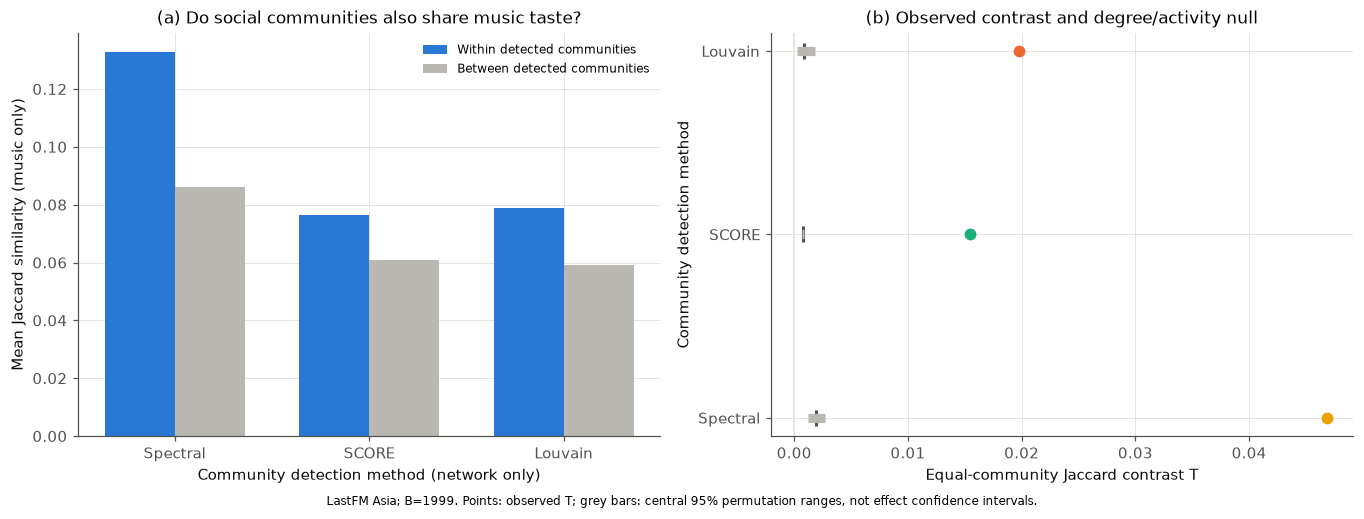

In [16]:
# Main figure: the original community detection comparison and independent music evaluation
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
x = np.arange(len(CORE_METHODS))
same = main_tab.loc[CORE_METHODS, 'S_same'].to_numpy()
different = main_tab.loc[CORE_METHODS, 'S_diff'].to_numpy()
axs[0].bar(x - .18, same, width=.36, color=METHOD_COLOR[DETAIL_METHOD], label='Within detected communities')
axs[0].bar(x + .18, different, width=.36, color=OTHER, label='Between detected communities')
axs[0].set_xticks(x, CORE_METHODS)
axs[0].set(xlabel='Community detection method (network only)', ylabel='Mean Jaccard similarity (music only)',
           title='(a) Do social communities also share music taste?')
axs[0].legend(fontsize=8)
for j, method in enumerate(CORE_METHODS):
    result = main_res[method]
    axs[1].plot([result['null_q025'], result['null_q975']], [j, j], color=OTHER, lw=6, solid_capstyle='butt')
    axs[1].scatter(result['null_mean'], j, marker='|', s=100, color=INK2)
    axs[1].scatter(result['T'], j, color=METHOD_COLOR[method], s=45, zorder=3)
axs[1].axvline(0, color=GRID, lw=1)
axs[1].set_yticks(range(len(CORE_METHODS)), CORE_METHODS)
axs[1].set(xlabel='Equal-community Jaccard contrast T', ylabel='Community detection method',
           title='(b) Observed contrast and degree/activity null')
fig.text(.5, -.01, f'LastFM Asia; B={B_MAIN}. Points: observed T; grey bars: central 95% permutation ranges, not effect confidence intervals.', ha='center', fontsize=8)
fig.tight_layout(); savefig(fig, 'fig06_permutation_nulls'); plt.show()

### 4.1 Detailed community profiles: truncated SCORE+ extension
This illustrates one fitted partition; it does not replace the three-method comparison.

,size,within-community similarity,mean similarity to other communities,lift (within / other),mean degree,top country share
community,,,,,,
0,1892,0.074,0.062,1.186,7.221,0.527
1,1261,0.089,0.062,1.450,7.309,0.863
2,1009,0.081,0.061,1.326,6.948,0.746
3,946,0.084,0.065,1.304,7.505,0.462
4,645,0.050,0.047,1.073,5.329,0.828
5,555,0.060,0.049,1.220,6.243,0.550
6,325,0.081,0.061,1.335,10.542,0.714
7,304,0.077,0.058,1.326,8.536,0.875
8,212,0.110,0.059,1.853,9.646,0.632


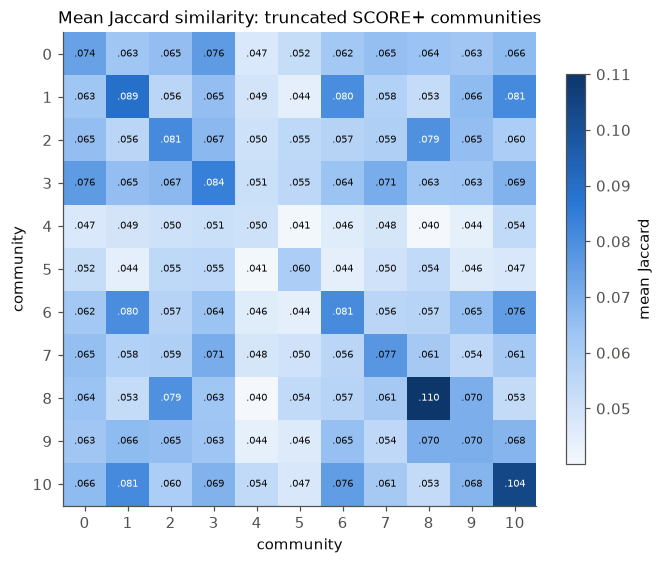

In [17]:
res_sp = T_stat(S, partitions[DETAIL_METHOD], full=True)
Kp = len(res_sp['sizes'])
Mmat = res_sp['between'].copy(); np.fill_diagonal(Mmat, res_sp['within'])
off = ~np.eye(Kp, dtype=bool)
comm_tab = pd.DataFrame({
    'size': res_sp['sizes'].astype(int),
    'within-community similarity': res_sp['within'],
    'mean similarity to other communities': np.array([Mmat[k, off[k]].mean() for k in range(Kp)]),
})
comm_tab['lift (within / other)'] = comm_tab.iloc[:, 1] / comm_tab.iloc[:, 2]
comm_tab['mean degree'] = [deg[partitions[DETAIL_METHOD] == k].mean() for k in range(Kp)]
comm_tab['top country share'] = [pd.Series(country[partitions[DETAIL_METHOD] == k]).value_counts(normalize=True).iloc[0] for k in range(Kp)]
comm_tab.index.name = 'community'
savetab(comm_tab.round(4), 'tab07_scoreplus_communities', index=True)
display(comm_tab.round(3))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(Mmat, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b']))
ax.set_xticks(range(Kp)); ax.set_yticks(range(Kp)); ax.grid(False)
for i in range(Kp):
    for j in range(Kp):
        ax.text(j, i, f'{Mmat[i,j]:.3f}'[1:], ha='center', va='center', fontsize=6.5,
                color='white' if Mmat[i, j] > Mmat.min() + 0.55 * (Mmat.max() - Mmat.min()) else INK)
ax.set(xlabel='community', ylabel='community', title='Mean Jaccard similarity: truncated SCORE+ communities')
fig.colorbar(im, ax=ax, shrink=0.8, label='mean Jaccard')
fig.tight_layout(); savefig(fig, 'fig05_similarity_matrix'); plt.show()

**Community descriptions.** The block similarity matrix and community characteristics are descriptive. They do not supply independent community-level significance tests. Compare the within-community similarity to the appropriate between-community mean and inspect country composition before attaching a substantive interpretation. Anonymous artist IDs do not identify a genre.

## 5. Does the method choice change the answer?
Spectral versus SCORE examines degree correction. Spectral methods versus Louvain examine agreement across different approaches. SCORE+ is a documented extension.

In [18]:
labs_cmp = {**partitions, 'Louvain (γ=1)': louv_default}
names = list(labs_cmp)
nmi_mat = pd.DataFrame([[NMI(labs_cmp[a], labs_cmp[b]) for b in names] for a in names], index=names, columns=names)
savetab(nmi_mat.round(3), 'tab09_nmi_matrix', index=True)

hub = deg >= np.quantile(deg, 0.99)
hub_rows = []
for m in METHOD_ORDER:
    l = partitions[m]; sizes = np.bincount(l)
    hub_comm = pd.Series(l[hub]).value_counts()
    hub_rows.append({'Method': m,
                     '# communities containing top-1% hubs': len(hub_comm),
                     '% of hubs in communities with < 5% of users': 100 * np.mean(sizes[l[hub]] < 0.05 * n),
                     'corr(community size, mean degree)': pd.Series(sizes).corr(pd.Series([deg[l == k].mean() for k in range(len(sizes))]), method='spearman'),
                     'max mean degree / overall mean degree': max(deg[l == k].mean() for k in range(len(sizes))) / deg.mean()})
hub_tab = pd.DataFrame(hub_rows).set_index('Method')
savetab(hub_tab.round(3), 'tab10_hub_placement', index=True)

summary_tab = main_tab[['analysis_role', 'K', 'S_same', 'S_diff', 'T', 'ratio S_same/S_diff', 'p (perm)', 'p_Holm_primary_3_methods']].copy()
summary_tab['pair_weighted_T'] = [main_res[m]['pair_result']['T'] for m in summary_tab.index]
summary_tab['NMI with SCORE'] = [NMI(partitions[m], partitions['SCORE']) for m in summary_tab.index]
savetab(summary_tab, 'tab11_method_comparison', index=True)
display(summary_tab.loc[CORE_METHODS].round(5))
display(hub_tab.round(3))

,analysis_role,K,S_same,S_diff,T,ratio S_same/S_diff,p (perm),p_Holm_primary_3_methods,pair_weighted_T,NMI with SCORE
Method,,,,,,,,,,
Spectral,core_method,11,0.13284,0.08604,0.04680,1.54394,0.0005,0.0015,-0.01375,0.13127
SCORE,core_method,11,0.07631,0.06089,0.01542,1.25326,0.0005,0.0015,0.01634,1.00000
Louvain,core_method,11,0.07896,0.05921,0.01976,1.33370,0.0005,0.0015,0.01769,0.57776


,# communities containing top-1% hubs,% of hubs in communities with < 5% of users,"corr(community size, mean degree)",max mean degree / overall mean degree
Method,,,,
Spectral,10,90.667,-0.091,7.367
SCORE,10,13.333,-0.427,1.640
SCORE+ (paper),3,0.000,-0.073,1.303
SCORE+ (truncated),9,16.000,-0.309,1.448
Louvain,6,0.000,-0.082,1.285


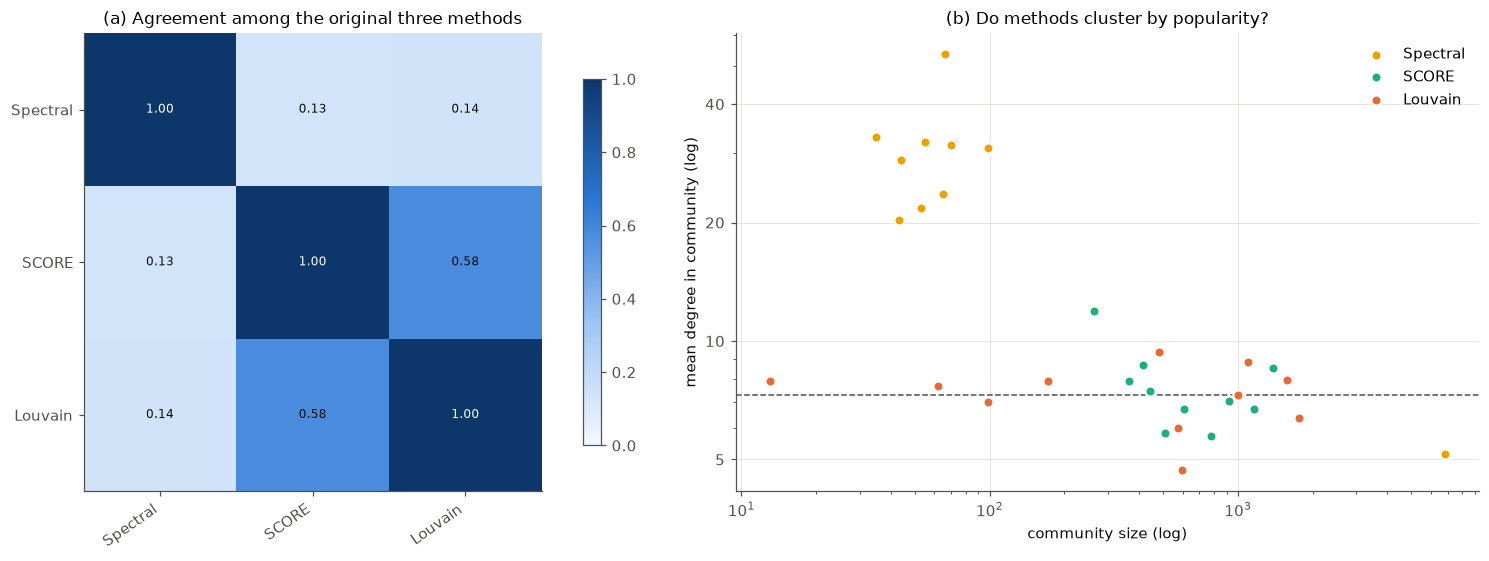

In [19]:
core_nmi = nmi_mat.loc[CORE_METHODS, CORE_METHODS]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
im = ax[0].imshow(core_nmi.values, vmin=0, vmax=1, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b']))
ax[0].set_xticks(range(len(CORE_METHODS))); ax[0].set_xticklabels(CORE_METHODS, rotation=35, ha='right'); ax[0].set_yticks(range(len(CORE_METHODS))); ax[0].set_yticklabels(CORE_METHODS)
ax[0].grid(False)
for i in range(len(CORE_METHODS)):
    for j in range(len(CORE_METHODS)):
        ax[0].text(j, i, f'{core_nmi.values[i,j]:.2f}', ha='center', va='center', fontsize=8, color='white' if core_nmi.values[i, j] > .6 else INK)
ax[0].set_title('(a) Agreement among the original three methods'); fig.colorbar(im, ax=ax[0], shrink=0.8)
for m in CORE_METHODS:
    l = partitions[m]; sizes = np.bincount(l)
    md_ = [deg[l == k].mean() for k in range(len(sizes))]
    ax[1].scatter(sizes, md_, s=45, color=METHOD_COLOR[m], label=m, edgecolor='white', linewidth=1.5, zorder=3)
ax[1].axhline(deg.mean(), color=INK2, ls='--', lw=1)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter()); ax[1].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax[1].set_yticks([5, 10, 20, 40])
ax[1].set(xlabel='community size (log)', ylabel='mean degree in community (log)', title='(b) Do methods cluster by popularity?')
ax[1].legend()
fig.tight_layout(); savefig(fig, 'fig07_method_comparison'); plt.show()

**Main interpretation.** Compare community sizes, hub placement, music contrasts and weighting sensitivity for Spectral, SCORE and Louvain. These directly answer whether degree correction or a different optimization approach changes the conclusions. Agreement is not accuracy: music coherence is external evidence and NMI measures agreement; only planted-label simulations provide a recovery metric. Keep SCORE+ findings clearly labeled as extensions.

## 6. Sensitivity analysis
These checks are exploratory and not a search for the largest effect. Report changes in $T$, Jaccard ratio and null-centered excess; all permutation counts and exceedances are saved. The coarse resolution $1/(B_{robust}+1)$ limits p-values. The separate Appendix B checks country/degree/activity binning, both SCORE+ implementations and community influence. Removing popular artists changes the similarity's denominator and the outcome itself, so an increased ratio is not by itself evidence for a stronger absolute effect or for social causation.

In [20]:
rob = []
def add(check, setting, method, lab, Sm=S, strata=STRATA_DA, stat=T_stat):
    r = perm_test(Sm, lab, strata, B_ROBUST, seed=SEED + 7, stat=stat)
    full = stat(Sm, lab, full=True)
    rob.append({'check': check, 'setting': setting, 'method': method, 'K': lab.max() + 1, 'T': r['T'],
                'S_same': full['S_same'], 'S_diff': full['S_diff'], 'T_pair': full.get('T_pair', np.nan), 'ratio': full['ratio'], 'z': r['z'], 'p': r['p'], 'B': r['B'], 'exceedances': r['exceedances'], 'null_mean': r['null_mean'], 'excess_T': r['excess_T']})
t0 = time.time()
# (1) K / gamma
for K in sorted(set([5, 8, K_STAR, 15, 20])):
    add('K', K, 'Spectral', spectral_labels(vecs_A, K))
    add('K', K, 'SCORE', score_labels(vecs_A, K))
    add('K', K, DETAIL_METHOD, scoreplus_labels(vals_L, vecs_L, K))
    add('K', K, PAPER_METHOD, scoreplus_labels(vals_L, vecs_L, K, truncate=False))
for gam in [0.1, 0.3, 0.5, 1.0]:
    add('gamma', gam, 'Louvain', louvain_labels(G, gam))
# (2) tau for SCORE+
for name, tau in [('0.3 d̄', 0.3 * deg.mean()), ('d̄', deg.mean()), ('3 d̄', 3 * deg.mean()), ('0.1 d_max', 0.1 * deg.max())]:
    v, V = leading_eigs(reg_laplacian(A, tau), 25)
    add('tau', name, DETAIL_METHOD, scoreplus_labels(v, V, K_STAR))
    add('tau', name, PAPER_METHOD, scoreplus_labels(v, V, K_STAR, truncate=False))
print(f'(1)-(2) done in {time.time()-t0:.0f}s')

(1)-(2) done in 74s


In [21]:
t0 = time.time()
order = np.argsort(-art_pop)
for frac in [0.01, 0.05, 0.10]:
    drop = order[:int(np.ceil(frac * X.shape[1]))]
    keep = np.setdiff1d(np.arange(X.shape[1]), drop)
    S_r = jaccard_matrix(X[:, keep])
    for m in METHOD_ORDER:
        add('drop popular artists', f'top {int(frac*100)}%', m, partitions[m], Sm=S_r)
        rob[-1].update(artists_retained=len(keep), users_with_no_remaining_artists=int(np.sum(np.asarray(X[:, keep].sum(1)).ravel() == 0)))
    del S_r
# Pair-weighted tests already reuse all B_MAIN main permutations in tab16; no redundant rerun.
print(f'(3)-(4) done in {time.time()-t0:.0f}s')
rob_tab = pd.DataFrame(rob)
savetab(rob_tab, 'tab12_robustness')
rob_tab.round(4)

(3)-(4) done in 41s
Out[21]: 
                   check  ...  users_with_no_remaining_artists
0                      K  ...                              NaN
1                      K  ...                              NaN
2                      K  ...                              NaN
3                      K  ...                              NaN
4                      K  ...                              NaN
5                      K  ...                              NaN
6                      K  ...                              NaN
7                      K  ...                              NaN
8                      K  ...                              NaN
9                      K  ...                              NaN
10                     K  ...                              NaN
11                     K  ...                              NaN
12                     K  ...                              NaN
13                     K  ...                              NaN
14                     K 

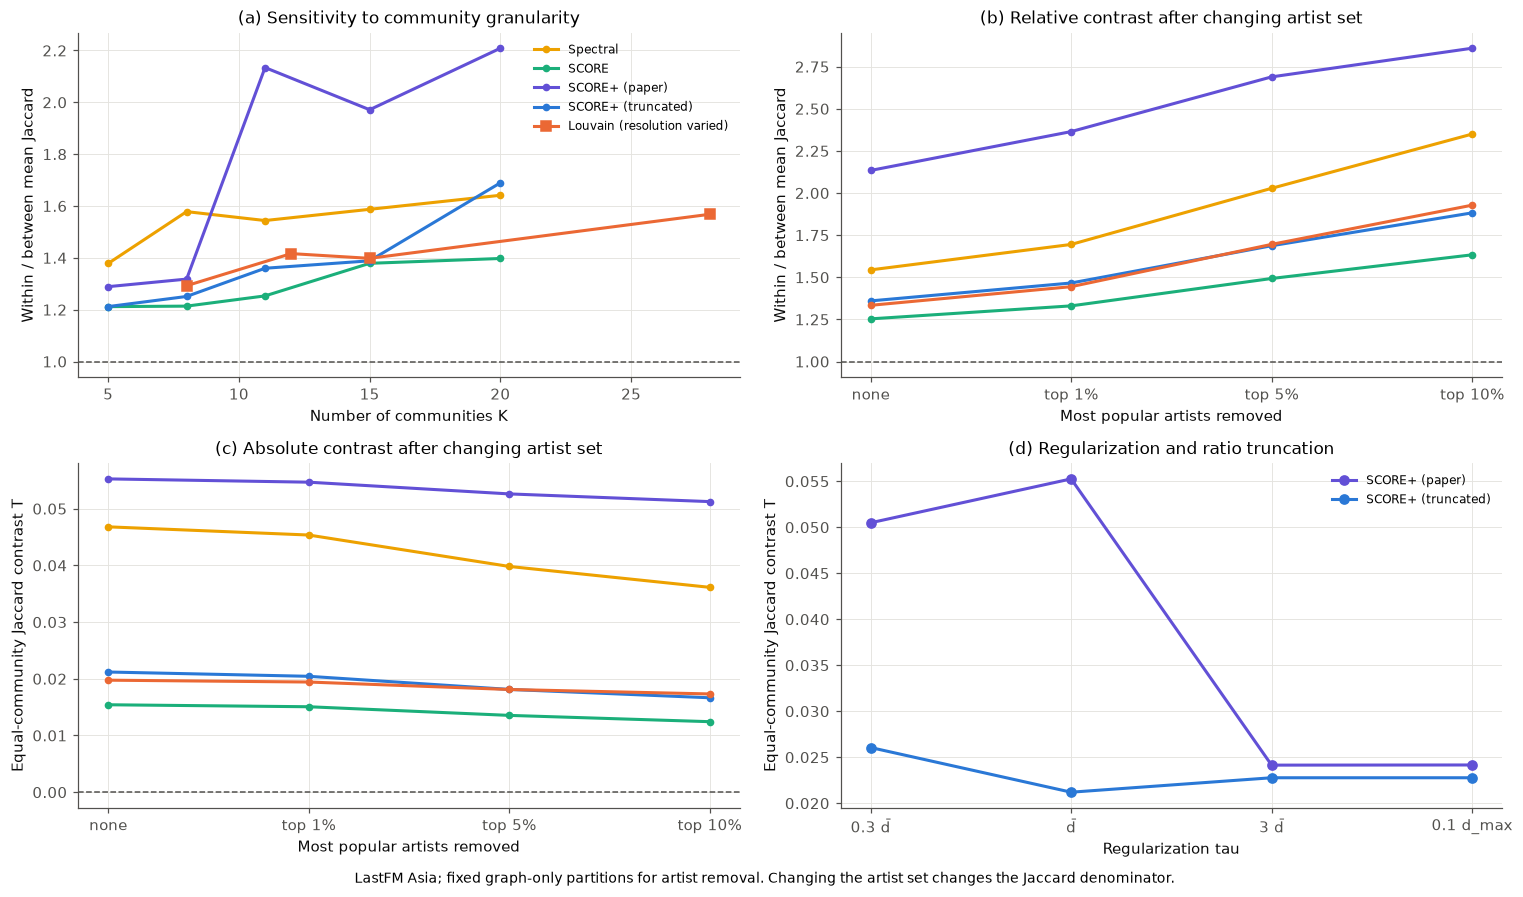

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
rk = rob_tab[rob_tab.check == 'K']
for method in METHOD_ORDER[:-1]:
    group = rk[rk.method == method]
    axs[0, 0].plot(group.setting.astype(int), group.ratio, marker='o', ms=4, color=METHOD_COLOR[method], label=method)
group = rob_tab[rob_tab.check == 'gamma']
axs[0, 0].plot(group.K, group.ratio, marker='s', color=METHOD_COLOR['Louvain'], label='Louvain (resolution varied)')
axs[0, 0].axhline(1, color=INK2, lw=1, ls='--')
axs[0, 0].set(xlabel='Number of communities K', ylabel='Within / between mean Jaccard', title='(a) Sensitivity to community granularity')
axs[0, 0].legend(fontsize=8)

dp = rob_tab[rob_tab.check == 'drop popular artists']
xs = ['none', 'top 1%', 'top 5%', 'top 10%']
for method in METHOD_ORDER:
    group = dp[dp.method == method]
    ratio_values = [main_tab.loc[method, 'ratio S_same/S_diff']] + list(group.ratio)
    contrast_values = [main_tab.loc[method, 'T']] + list(group['T'])
    axs[0, 1].plot(xs, ratio_values, marker='o', ms=4, color=METHOD_COLOR[method], label=method)
    axs[1, 0].plot(xs, contrast_values, marker='o', ms=4, color=METHOD_COLOR[method], label=method)
axs[0, 1].axhline(1, color=INK2, lw=1, ls='--')
axs[1, 0].axhline(0, color=INK2, lw=1, ls='--')
axs[0, 1].set(xlabel='Most popular artists removed', ylabel='Within / between mean Jaccard', title='(b) Relative contrast after changing artist set')
axs[1, 0].set(xlabel='Most popular artists removed', ylabel='Equal-community Jaccard contrast T', title='(c) Absolute contrast after changing artist set')

dt = rob_tab[rob_tab.check == 'tau']
for method in [PAPER_METHOD, DETAIL_METHOD]:
    group = dt[dt.method == method]
    axs[1, 1].plot(group.setting.astype(str), group['T'], color=METHOD_COLOR[method], marker='o', label=method)
axs[1, 1].set(xlabel='Regularization tau', ylabel='Equal-community Jaccard contrast T', title='(d) Regularization and ratio truncation')
axs[1, 1].legend(fontsize=8)
fig.text(.5, -.01, 'LastFM Asia; fixed graph-only partitions for artist removal. Changing the artist set changes the Jaccard denominator.', ha='center', fontsize=9)
fig.tight_layout(); savefig(fig, 'fig08_robustness'); plt.show()

**Interpretation rule.** Inspect both absolute and relative contrasts. Removing common artists changes the scale of Jaccard similarity. K and regularization choices can alter the partition itself. Do not call the result robust merely because a one-sided test rejects at one setting; inspect sign, magnitude, exchangeability support and sensitivity to weighting.

## 7. Network illustrations
These are descriptive illustrations of the **truncated SCORE+ variant**. The fixed layout is reused only when it matches the exact ordered node IDs and graph signature. Layout positions do not enter estimation, tuning, or inference. The community graph uses group size as area, observed edge count as width, and within-group Jaccard mean as color; edge widths are not adjusted for group sizes.

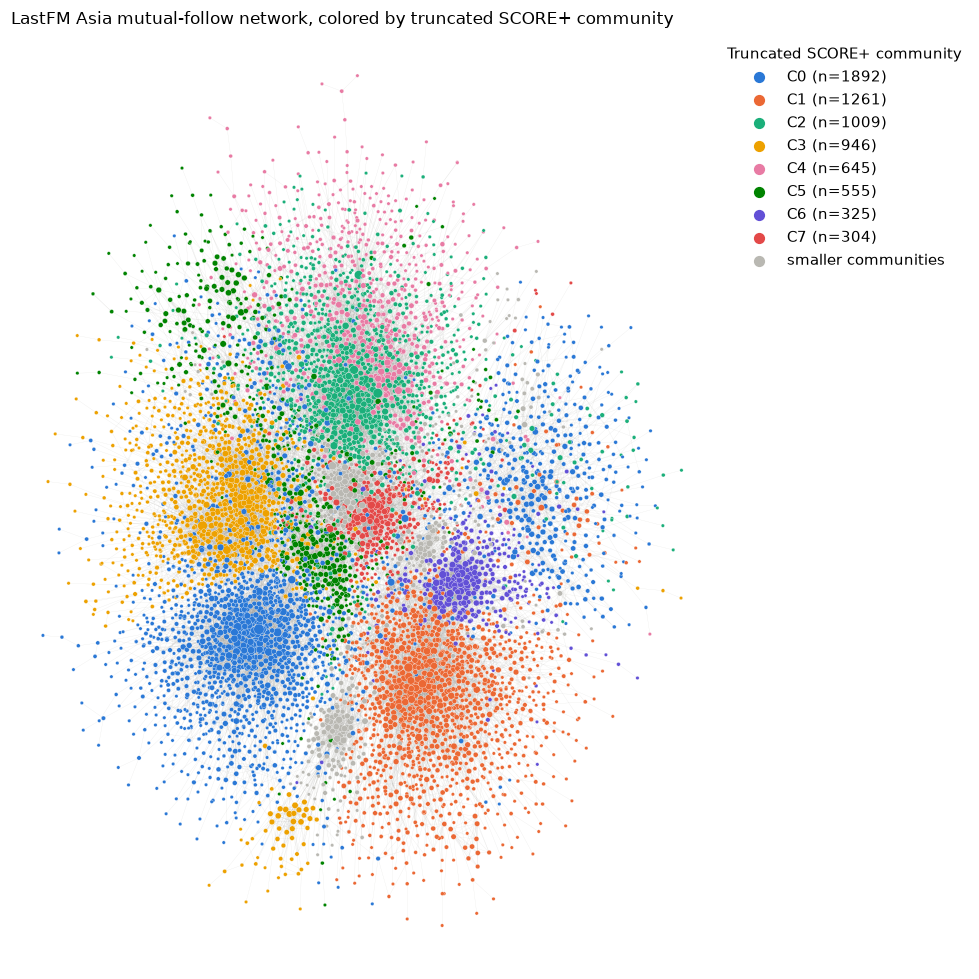

In [23]:
lay_path = os.path.join(OUT_DIR, 'layout.npy')
layout_signature = hashlib.sha256(nodes.tobytes() + A.indices.tobytes() + A.indptr.tobytes()).hexdigest()
layout_meta_path = os.path.join(OUT_DIR, 'layout_metadata.json')
layout_ok = os.path.exists(lay_path) and os.path.exists(layout_meta_path) and json.loads(Path(layout_meta_path).read_text()).get('signature') == layout_signature
if layout_ok:
    pos = np.load(lay_path)
else:
    random.seed(SEED)
    gi = ig.Graph(n=n, edges=list(zip(*sp.triu(A).nonzero())))
    ig.set_random_number_generator(random.Random(SEED))
    initial = np.random.default_rng(SEED).normal(size=(n, 2)).tolist()
    pos = np.array(gi.layout_fruchterman_reingold(niter=1500, seed=initial).coords)
    np.save(lay_path, pos)
    Path(layout_meta_path).write_text(json.dumps({'signature': layout_signature, 'seed': SEED, 'node_count': n}, indent=2))
assert pos.shape == (n, 2) and np.isfinite(pos).all()

lab = partitions[DETAIL_METHOD]
col = np.array([CAT8[k] if k < 8 else OTHER for k in lab])
fig, ax = plt.subplots(figsize=(9, 9))
eu, ev = sp.triu(A).nonzero()
segs = np.stack([pos[eu], pos[ev]], axis=1)
ax.add_collection(mpl.collections.LineCollection(segs, colors='#9a9993', linewidths=0.15, alpha=0.25, zorder=1))
ax.scatter(pos[:, 0], pos[:, 1], s=2 + 3 * np.sqrt(deg), c=col, edgecolor='white', linewidth=0.2, zorder=2)
for k in range(min(8, lab.max() + 1)):
    ax.scatter([], [], s=40, color=CAT8[k], label=f'C{k} (n={np.sum(lab==k)})')
if lab.max() >= 8:
    ax.scatter([], [], s=40, color=OTHER, label='smaller communities')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Truncated SCORE+ community')
ax.set_axis_off(); ax.set_title('LastFM Asia mutual-follow network, colored by truncated SCORE+ community', loc='left')
fig.tight_layout(); savefig(fig, 'fig09_network'); plt.show()

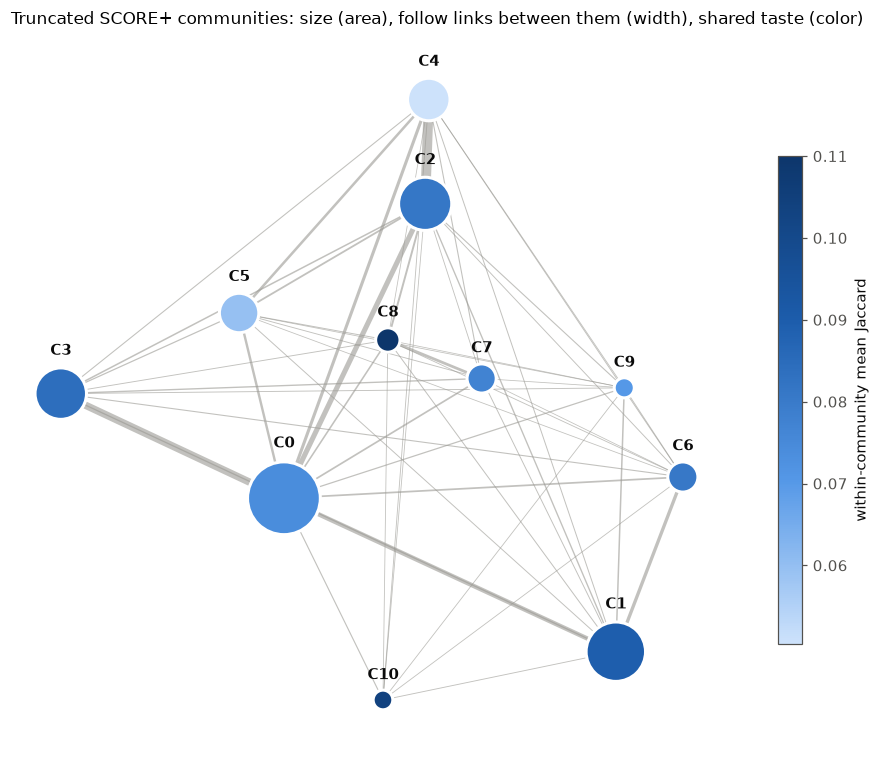

In [24]:
Zc = onehot(lab)
Ec = (Zc.T @ (A @ Zc)).astype(float)       # follow links between communities (diag counts each edge twice)
cent = np.array([pos[lab == k].mean(0) for k in range(Kp)])
fig, ax = plt.subplots(figsize=(8.5, 7))
wmax = max(Ec[i, j] for i in range(Kp) for j in range(Kp) if i != j)
for i in range(Kp):
    for j in range(i + 1, Kp):
        if Ec[i, j] > 0:
            ax.plot(*zip(cent[i], cent[j]), color='#9a9993', lw=0.5 + 6 * Ec[i, j] / wmax, alpha=0.6, zorder=1)
cmap = mpl.colors.LinearSegmentedColormap.from_list('b', ['#cde2fb', '#5598e7', '#1c5cab', '#0d366b'])
sizes_pt = np.maximum(res_sp['sizes'] * 1.2, 120)
sc = ax.scatter(cent[:, 0], cent[:, 1], s=sizes_pt, c=res_sp['within'], cmap=cmap, edgecolor='white', linewidth=2, zorder=2)
for k in range(Kp):
    r_pt = np.sqrt(sizes_pt[k] / np.pi)
    ax.annotate(f'C{k}', cent[k], xytext=(0, r_pt + 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=10, color=INK, weight='bold', zorder=3)
fig.colorbar(sc, ax=ax, shrink=0.7, label='within-community mean Jaccard')
ax.margins(0.08)
ax.set_axis_off(); ax.set_title('Truncated SCORE+ communities: size (area), follow links between them (width), shared taste (color)', loc='left', pad=18)
fig.tight_layout(); savefig(fig, 'fig10_community_graph'); plt.show()

## Appendix A. Recovery under calibrated Poissonized DCBM and SBM generators

The real labels are unknown. We construct three **model-conditional** experiments: degree heterogeneity with truncated SCORE+ planted labels; degree heterogeneity with Louvain planted labels; homogeneous propensities within each block with truncated SCORE+ planted labels.

For block pair $k<l$, draw a Poisson number of edges with mean equal to the observed cross-block count and sample endpoints with probabilities $w_i=d_i/\sum_{j:c_j=k}d_j$. Within a block use its observed undirected edge count. The independent Poisson multiplicity for $i<j$ has mean $\lambda_{ij}=m_{kl}w_iw_j$ across blocks and $2m_{kk}w_iw_j$ within blocks. After merging multiple edges, $P(A_{ij}=1)=1-e^{-\lambda_{ij}}$. Thus this is a **Poissonized degree-corrected generator**, not exactly the linear Bernoulli DCBM above. In the homogeneous setting, expected degree may still differ **between** blocks. Removing self-loops, merging duplicates, and selecting the LCC change expected degrees; retained sample size and recovery group counts are recorded.

Every method sees the same graph within a replicate. Spectral methods receive the planted number of groups (an oracle advantage); Louvain uses the real-data resolution and selects its own group count. NMI and ARI are label-invariant recovery metrics. Report means, SD, Monte Carlo standard errors and t intervals over independent graph replicates, plus paired differences. These intervals concern mean performance under this generator, not uncertainty about real communities. Calibrating to two fitted partitions reduces but does not remove model favoritism.

In [25]:
def sample_dcbm(truth, deg_weights, r):
    K = truth.max() + 1
    Zt = onehot(truth)
    Mkl = (Zt.T @ (A @ Zt)).astype(float)
    members = [np.where(truth == k)[0] for k in range(K)]
    probs = [deg_weights[m] / deg_weights[m].sum() for m in members]
    us, vs = [], []
    for k in range(K):
        for l in range(k, K):
            lam = Mkl[k, k] / 2 if k == l else Mkl[k, l]
            m_ = r.poisson(lam)
            us.append(r.choice(members[k], m_, p=probs[k])); vs.append(r.choice(members[l], m_, p=probs[l]))
    u, v = np.concatenate(us), np.concatenate(vs)
    keep = u != v
    Bm = sp.coo_matrix((np.ones(keep.sum()), (u[keep], v[keep])), shape=(n, n)).tocsr()
    Bm = ((Bm + Bm.T) > 0).astype(float).tocsr()
    _, comp = sp.csgraph.connected_components(Bm, directed=False)
    cc = np.where(comp == np.bincount(comp).argmax())[0]
    return Bm[cc][:, cc].tocsr(), cc

def run_methods(Am, K):
    v_a, V_a = leading_eigs(Am, K + 2)
    d_ = np.asarray(Am.sum(1)).ravel()
    v_l, V_l = leading_eigs(reg_laplacian(Am, d_.mean()), K + 2)
    Gs = nx.from_scipy_sparse_array(Am)
    return {'Spectral': spectral_labels(V_a, K), 'SCORE': score_labels(V_a, K), PAPER_METHOD: scoreplus_labels(v_l, V_l, K, truncate=False),
            DETAIL_METHOD: scoreplus_labels(v_l, V_l, K), 'Louvain': louvain_labels(Gs, GAMMA, nodelist=np.arange(Am.shape[0]))}

settings = [('Poisson DCBM: truncated SCORE+ truth', partitions[DETAIL_METHOD], deg),
            ('Poisson DCBM: Louvain truth', partitions['Louvain'], deg),
            ('Homogeneous blocks: truncated SCORE+ truth', partitions[DETAIL_METHOD], np.ones(n))]
sim_rows = []
t0 = time.time()
for setting_index, (sname, truth, w) in enumerate(settings):
    for rep in range(N_SIM):
        r = np.random.default_rng(SEED + 99 + 1000 * setting_index + rep)
        Am, cc = sample_dcbm(truth, w, r)
        tr = relabel_by_size(truth[cc])
        out = run_methods(Am, truth.max() + 1)
        for m, l in out.items():
            sim_rows.append({'setting': sname, 'rep': rep, 'method': m, 'NMI': NMI(tr, l), 'ARI': ARI(tr, l), 'n_lcc': len(cc), 'retained_fraction': len(cc) / n, 'estimated_K': len(np.unique(l)), 'planted_K': len(np.unique(truth)), 'planted_K_in_lcc': len(np.unique(tr)), 'm_lcc': Am.nnz // 2})
print(f'simulation done in {time.time()-t0:.0f}s')
sim = pd.DataFrame(sim_rows)
savetab(sim, 'tabA1_simulation_raw')

sim_summary_rows = []
for (setting, method), group in sim.groupby(['setting', 'method'], sort=False):
    row = {'setting': setting, 'method': method, 'replications': len(group),
           'mean_retained_fraction': group.retained_fraction.mean(), 'mean_estimated_K': group.estimated_K.mean()}
    for metric in ['NMI', 'ARI']:
        values = group[metric]
        sd = values.std(ddof=1) if len(values) > 1 else np.nan
        mcse = sd / np.sqrt(len(values))
        half = student_t.ppf(.975, len(values)-1) * mcse if len(values) > 1 else np.nan
        row.update({metric + '_mean': values.mean(), metric + '_sd': sd, metric + '_mcse': mcse,
                    metric + '_mean_ci_low': values.mean() - half, metric + '_mean_ci_high': values.mean() + half})
    sim_summary_rows.append(row)
sim_tab = pd.DataFrame(sim_summary_rows)
savetab(sim_tab, 'tabA2_simulation_summary')
paired_rows = []
for setting, group in sim.groupby('setting', sort=False):
    pivot = group.pivot(index='rep', columns='method', values='NMI')
    for other in METHOD_ORDER:
        if other == DETAIL_METHOD:
            continue
        difference = pivot[DETAIL_METHOD] - pivot[other]
        mcse = difference.std(ddof=1) / np.sqrt(len(difference)) if len(difference) > 1 else np.nan
        half = student_t.ppf(.975, len(difference)-1) * mcse if len(difference) > 1 else np.nan
        paired_rows.append(dict(setting=setting, comparison=DETAIL_METHOD + ' minus ' + other,
            mean_NMI_difference=difference.mean(), mcse=mcse, ci_low=difference.mean()-half,
            ci_high=difference.mean()+half, replications=len(difference)))
savetab(pd.DataFrame(paired_rows), 'tabA3_simulation_paired_differences')
sim_tab.round(4)

simulation done in 40s
Out[25]: 
                                       setting  ...  ARI_mean_ci_high
0         Poisson DCBM: truncated SCORE+ truth  ...            0.0290
1         Poisson DCBM: truncated SCORE+ truth  ...            0.7102
2         Poisson DCBM: truncated SCORE+ truth  ...            0.8109
3         Poisson DCBM: truncated SCORE+ truth  ...            0.8530
4         Poisson DCBM: truncated SCORE+ truth  ...            0.6895
5                  Poisson DCBM: Louvain truth  ...            0.0214
6                  Poisson DCBM: Louvain truth  ...            0.5794
7                  Poisson DCBM: Louvain truth  ...            0.2839
8                  Poisson DCBM: Louvain truth  ...            0.8871
9                  Poisson DCBM: Louvain truth  ...            0.9628
10  Homogeneous blocks: truncated SCORE+ truth  ...            0.6744
11  Homogeneous blocks: truncated SCORE+ truth  ...            0.6992
12  Homogeneous blocks: truncated SCORE+ truth  ...      

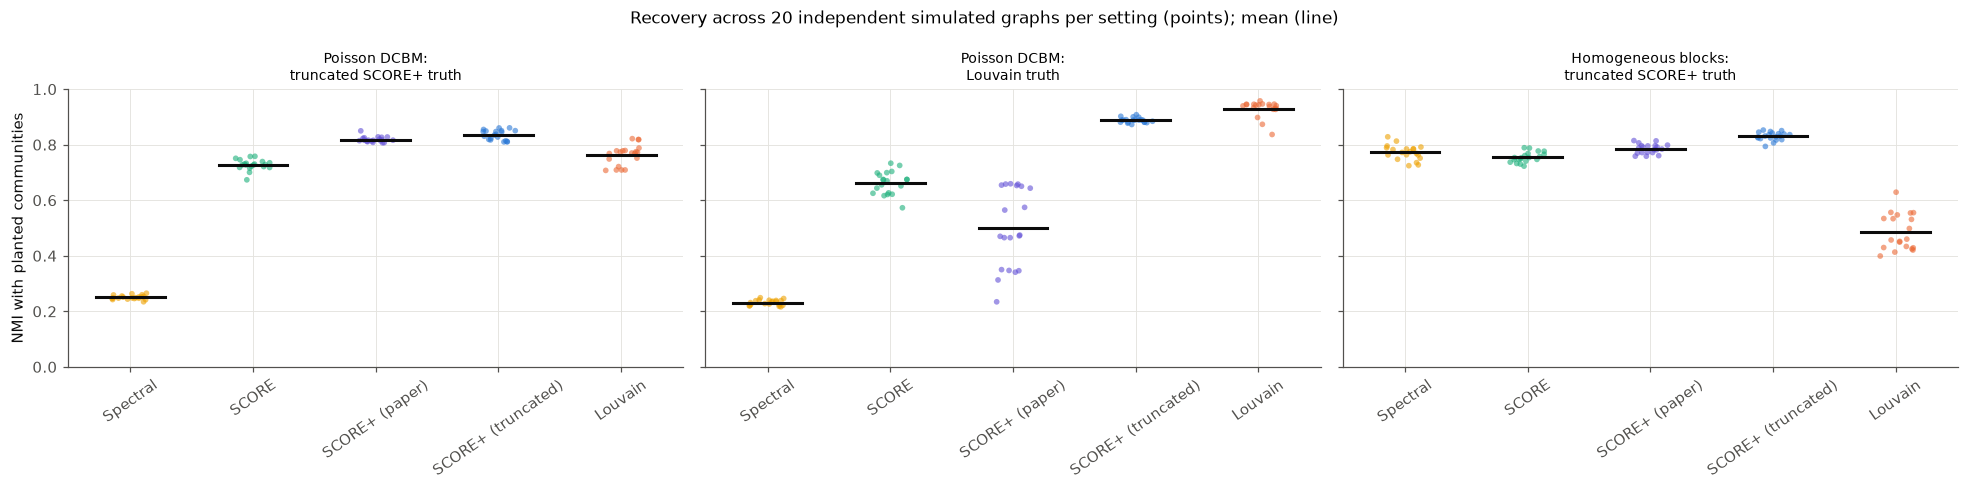

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for a, (sname, _, _) in zip(axs, settings):
    d_ = sim[sim.setting == sname]
    for j, m in enumerate(METHOD_ORDER):
        y = d_[d_.method == m].NMI.values
        a.scatter(np.full(len(y), j) + np.random.default_rng(j).uniform(-0.15, 0.15, len(y)), y, s=14, color=METHOD_COLOR[m], alpha=0.6, edgecolor='none')
        a.plot([j - 0.28, j + 0.28], [y.mean()] * 2, color=INK, lw=2)
    a.set_xticks(range(len(METHOD_ORDER))); a.set_xticklabels(METHOD_ORDER); a.set_title(sname.replace(': ', ':\n'), fontsize=9)
    a.tick_params(axis='x', labelrotation=35)
    a.set_ylim(0, 1)
axs[0].set_ylabel('NMI with planted communities')
fig.suptitle(f'Recovery across {N_SIM} independent simulated graphs per setting (points); mean (line)', fontsize=11)
fig.tight_layout(); savefig(fig, 'figA1_simulation'); plt.show()

**Interpretation rule.** Use paired recovery differences and their Monte Carlo uncertainty to state which methods work under which generators. Do not turn these calibrated experiments into a universal method ranking. In particular, the homogeneous and heterogeneous generators alter multiple graph properties after simplification and LCC selection, so their difference supports a mechanism without uniquely proving the cause of the real-data failure.

## 8. Reproducibility and findings

In [27]:
choices = pd.DataFrame([
    ('Sample', f'LCC of users with music data: n = {n:,}, m = {G.number_of_edges():,}'),
    ('Eigen-decomposition', 'scipy.sparse.linalg.eigsh, deterministic v0, tol=1e-11; positive entrywise Perron refinement; top 30 by magnitude'),
    ('k-means', f'scikit-learn KMeans, {N_INIT} random starts, seed {SEED}'),
    ('Number of communities K', f'K* = {K_STAR}: largest relative eigengap of L_τ in 3..20; checked with community sizes and edge-subsampling stability (no music data used)'),
    ('SCORE truncation', 'SCORE: truncated at +/-log n; truncated SCORE+ extension: clipped; paper comparator: untruncated'),
    ('SCORE+ regularization τ', f'tau=mean degree={deg.mean():.2f}, an explicit modification; published 0.1*dmax={0.1*deg.max():.1f} tested for both SCORE+ variants'),
    ('SCORE+ threshold t', 't=0.1; extra-vector rule uses signed eigenvalue ratio as in paper section 3.1'),
    ('Louvain', f'networkx.community.louvain_communities defaults; resolution γ = {GAMMA} chosen so K ≈ K* (default γ=1 gives K = {louv_default.max()+1}); seed {SEED}'),
    ('Similarity', 'Jaccard of binary liked-artist sets, float64, zero diagonal and empty-union convention'),
    ('Test statistic', 'T = mean of within-community means − mean of between-community means'),
    ('Permutation strata', 'tie-preserving quantile bins: degree/activity q5; country only; supplementary joint country/degree/activity q3; q5/q7 sensitivity'),
    ('# permutations', f'{B_MAIN} for the degree/activity main test; {B_COUNTRY} for country checks; {B_ROBUST} for other sensitivities; paired estimands share draws'),
    ('Simulation', f'Poissonized DCBM and within-block homogeneous SBM, calibrated to real block edge counts, {N_SIM} replications per setting'),
], columns=['Choice', 'Value'])
savetab(choices, 'tab13_implementation_choices')
choices

Out[27]: 
                     Choice                                              Value
0                    Sample  LCC of users with music data: n = 7,431, m = 2...
1       Eigen-decomposition  scipy.sparse.linalg.eigsh, deterministic v0, t...
2                   k-means    scikit-learn KMeans, 20 random starts, seed 236
3   Number of communities K  K* = 11: largest relative eigengap of L_τ in 3...
4          SCORE truncation  SCORE: truncated at +/-log n; truncated SCORE+...
5   SCORE+ regularization τ  tau=mean degree=7.28, an explicit modification...
6        SCORE+ threshold t  t=0.1; extra-vector rule uses signed eigenvalu...
7                   Louvain  networkx.community.louvain_communities default...
8                Similarity  Jaccard of binary liked-artist sets, float64, ...
9            Test statistic  T = mean of within-community means − mean of b...
10       Permutation strata  tie-preserving quantile bins: degree/activity ...
11           # permutations  1999 for the 

### Findings follow the original research question
The final summary compares Spectral, SCORE and Louvain on network-derived communities and independently measured music similarity. SCORE+ provides a documented method extension. Country checks are supplementary.

### Report narrative
1. What communities are detected from the follow network alone?
2. Is music taste more similar within those communities than between them?
3. Does the conclusion change when correcting degree heterogeneity (Spectral versus SCORE) or changing method family (spectral methods versus Louvain)?

Explain SCORE+ separately as a motivated extension. Country belongs in a short confounding sensitivity discussion or appendix. Interpret association, estimator weighting and method disagreement without causal claims.

### Limits that must carry into the report
- Observational association cannot distinguish selection, peer influence, or shared unmeasured factors.
- Within-stratum joint exchangeability is assumed, not established by preserving dyads in a permutation. Binning only approximately adjusts for continuous covariates.
- Inference conditions on one observed graph and fitted partition; it does not include uncertainty about a population network or true labels. Perturbation stability is a sensitivity diagnostic, not a population confidence interval.
- Likes and country labels are anonymized; the artist release is filtered and omits much of the long tail. A larger Jaccard ratio after artist removal is not a count-of-artists effect or causal evidence.
- Complete-case/LCC selection can bias the target population. Data-source counts alone do not establish byte-for-byte identity with SNAP; local file hashes establish reproducibility of this copy.
- The detailed community illustration uses a truncated SCORE+ modification. The untruncated paper comparator and published regularization must remain visible.
- Network models assume hard communities and conditional edge independence; real graphs may have overlapping memberships and transitivity beyond the model. Calibrated recovery experiments do not verify model fit.
- Analysis choices were revised after viewing earlier results. Sensitivity analyses are exploratory; Holm adjustment addresses the stated primary three-method family, not all analytical choices.

In [28]:
print('Figures:', sorted(os.listdir(FIG_DIR)))
print('Tables :', sorted(os.listdir(TAB_DIR)))

Figures: ['fig01_degree_artists.pdf', 'fig01_degree_artists.png', 'fig02_localization.pdf', 'fig02_localization.png', 'fig03_K_selection.pdf', 'fig03_K_selection.png', 'fig04_community_sizes.pdf', 'fig04_community_sizes.png', 'fig05_similarity_matrix.pdf', 'fig05_similarity_matrix.png', 'fig06_permutation_nulls.pdf', 'fig06_permutation_nulls.png', 'fig07_method_comparison.pdf', 'fig07_method_comparison.png', 'fig08_robustness.pdf', 'fig08_robustness.png', 'fig09_network.pdf', 'fig09_network.png', 'fig10_community_graph.pdf', 'fig10_community_graph.png', 'fig11_core_networks.pdf', 'fig11_core_networks.png', 'fig12_core_music_heatmaps.pdf', 'fig12_core_music_heatmaps.png', 'fig13_weighting_sensitivity.pdf', 'fig13_weighting_sensitivity.png', 'figA1_simulation.pdf', 'figA1_simulation.png', 'figB1_country_sensitivity.pdf', 'figB1_country_sensitivity.png', 'visualization_review.pdf']
Tables : ['tab00_report_rubric_evidence.csv', 'tab01_data_summary.csv', 'tab02_localization.csv', 'tab03_K_s

### References
- Rozemberczki, B. and Sarkar, R. (2020). Characteristic functions on graphs: birds of a feather, from statistical descriptors to parametric models. *CIKM*.
- Jin, J. (2015). Fast community detection by SCORE. *Annals of Statistics* 43(1), 57–89.
- Jin, J., Ke, Z. T. and Luo, S. (2021). Improvements on SCORE, especially for weak signals. *Sankhya A* 84, 127–162.
- Karrer, B. and Newman, M. E. J. (2011). Stochastic blockmodels and community structure in networks. *Physical Review E* 83, 016107.
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R. and Lefebvre, E. (2008). Fast unfolding of communities in large networks. *J. Stat. Mech.* P10008.
- Qin, T. and Rohe, K. (2013). Regularized spectral clustering under the degree-corrected stochastic blockmodel. *NeurIPS*.
- Phipson, B. and Smyth, G. K. (2010). [Permutation P-values should never be zero](https://gksmyth.github.io/pubs/PermPValuesPreprint.pdf). *Statistical Applications in Genetics and Molecular Biology* 9(1), Article 39.
- Hemerik, J. and Goeman, J. (2018). [Exact testing with random permutations](https://pmc.ncbi.nlm.nih.gov/articles/PMC6405018/). *TEST* 27, 811-825.

Primary algorithm/data sources: [SCORE](https://arxiv.org/abs/1211.5803), [SCORE+](https://arxiv.org/abs/1811.05927), [degree-corrected block models](https://arxiv.org/abs/1008.3926), and [SNAP LastFM Asia](https://snap.stanford.edu/data/feather-lastfm-social.html).

## Appendix B. Supplementary country checks, diagnostics, and report evidence
These materials support methodological assessment and robustness without replacing the two-source research question.

### B.1 Country as a supplementary confounding check
Country is not one of the two primary sources used to pose the research question. These optional checks ask whether geography could partly reproduce the observed association. They do not redefine communities, change graph fitting, or replace the main degree/activity test.

Country-only and country × degree × activity (three-bin) permutations are **supplementary**; finer joint bins are additional sensitivity checks. Their Monte Carlo counts and randomization support are reported. Small or unmixed strata can limit the information supplied by a reference.

The country-only null mean divided by observed T is descriptive, not a causal fraction explained. Rejecting a country-conditioned reference does not identify selection, influence or all unmeasured confounding.

In [29]:
STRATA_C = pd.factorize(country)[0]
STRATA_CDA = stats.combine_strata(STRATA_C, make_strata(deg, n_art, q=3))
t0 = time.time()
country_res = {m: perm_test(S, partitions[m], STRATA_C, B_COUNTRY, seed=SEED + 1) for m in METHOD_ORDER}
country_res2 = {m: perm_test(S, partitions[m], STRATA_CDA, B_COUNTRY, seed=SEED + 2) for m in METHOD_ORDER}
print(f'Country and joint references in {time.time()-t0:.0f}s')
inference_rows = []
null_arrays = {}
for scheme, results in [('degree_activity_q5', main_res), ('country', country_res), ('country_degree_activity_q3', country_res2)]:
    for m in METHOD_ORDER:
        for statistic, r in [('equal', results[m]), ('pair', results[m]['pair_result'])]:
            inference_rows.append(inference_row(m, r, scheme, statistic))
            null_arrays[f'{scheme}__{m}__{statistic}'] = r['null']
inference_tab = pd.DataFrame(inference_rows)
inference_tab['p_Holm_within_reference_10_tests'] = inference_tab.groupby('strata')['p'].transform(lambda v: stats.holm_adjust(v.values))
inference_tab['primary_family'] = (inference_tab.strata.eq(PRIMARY_REFERENCE)
    & inference_tab.Method.isin(CORE_METHODS) & inference_tab.statistic.eq('equal'))
inference_tab['analysis_role'] = np.select([
    inference_tab.primary_family,
    inference_tab.strata.str.startswith('country'),
    ~inference_tab.Method.isin(CORE_METHODS),
], ['primary_original_method', 'supplementary_country', 'SCORE+_extension'], default='pair_weighting_sensitivity')
inference_tab['p_Holm_primary_3_methods'] = np.nan
mask = inference_tab.primary_family
inference_tab.loc[mask, 'p_Holm_primary_3_methods'] = stats.holm_adjust(inference_tab.loc[mask, 'p'])
savetab(inference_tab, 'tab16_inference_all_references')
np.savez_compressed(os.path.join(OUT_DIR, 'permutation_nulls.npz'), **null_arrays)
country_tab = pd.DataFrame([{
    'Method': m, 'NMI with country': NMI(country, partitions[m]), 'T': r['T'],
    'null mean (within-country)': r['null_mean'], 'country null reproduction ratio (not causal)': r['null_mean'] / r['T'],
    'z (within-country)': r['z'], 'p (within-country)': r['p'],
    'joint null mean': country_res2[m]['null_mean'], 'joint excess T': country_res2[m]['excess_T'],
    'z (country x deg x activity)': country_res2[m]['z'], 'p (country x deg x activity)': country_res2[m]['p'],
} for m, r in country_res.items()]).set_index('Method').loc[METHOD_ORDER]
savetab(country_tab, 'tab08_country_check', index=True)
display(country_tab.round(5))
country_tab.round(5)

Country and joint references in 22s
Out[29]: 
                    NMI with country  ...  p (country x deg x activity)
Method                                ...                              
Spectral                     0.14027  ...                         0.005
SCORE                        0.50707  ...                         0.005
SCORE+ (paper)               0.39347  ...                         0.005
SCORE+ (truncated)           0.52449  ...                         0.005
Louvain                      0.63470  ...                         0.010

[5 rows x 10 columns]


,NMI with country,T,null mean (within-country),country null reproduction ratio (not causal),z (within-country),p (within-country),joint null mean,joint excess T,z (country x deg x activity),p (country x deg x activity)
Method,,,,,,,,,,
Spectral,0.14027,0.04680,0.01753,0.37457,27.32523,0.005,0.02765,0.01915,20.29809,0.005
SCORE,0.50707,0.01542,0.01000,0.64818,36.99899,0.005,0.01076,0.00466,35.52136,0.005
SCORE+ (paper),0.39347,0.05526,0.01238,0.22404,28.94193,0.005,0.01617,0.03909,34.36154,0.005
SCORE+ (truncated),0.52449,0.02120,0.01102,0.51997,61.90933,0.005,0.01183,0.00937,61.10894,0.005
Louvain,0.63470,0.01976,0.01414,0.71551,6.75942,0.005,0.01614,0.00362,3.17944,0.010


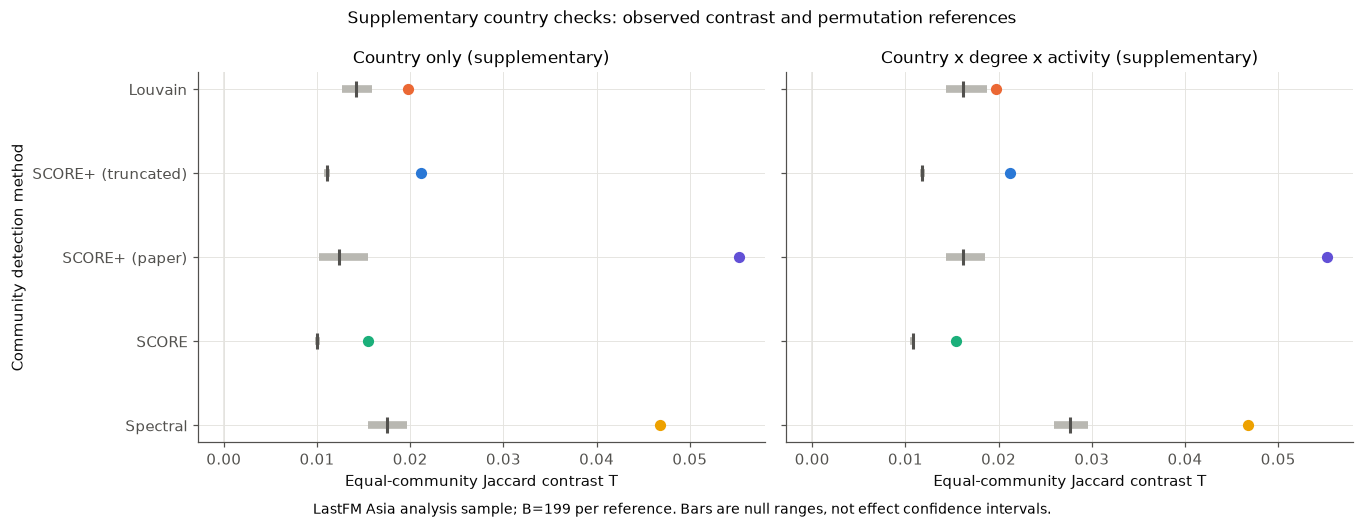

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for a, title, results in zip(axs, ['Country only (supplementary)', 'Country x degree x activity (supplementary)'], [country_res, country_res2]):
    for j, m in enumerate(METHOD_ORDER):
        r = results[m]
        a.plot([r['null_q025'], r['null_q975']], [j, j], color=OTHER, lw=5, solid_capstyle='butt')
        a.scatter(r['null_mean'], j, color=INK2, marker='|', s=100, zorder=3)
        a.scatter(r['T'], j, color=METHOD_COLOR[m], s=40, zorder=4)
    a.axvline(0, color=GRID, lw=1)
    a.set(title=title, xlabel='Equal-community Jaccard contrast T')
    a.set_yticks(range(len(METHOD_ORDER)), METHOD_ORDER)
axs[0].set_ylabel('Community detection method')
fig.suptitle('Supplementary country checks: observed contrast and permutation references', fontsize=11)
fig.text(0.5, -0.015, f'LastFM Asia analysis sample; B={B_COUNTRY} per reference. Bars are null ranges, not effect confidence intervals.', ha='center', fontsize=9)
fig.tight_layout(); savefig(fig, 'figB1_country_sensitivity'); plt.show()

**Supplementary interpretation.** Report country checks briefly in sensitivity analyses or the appendix. They address an alternative explanation for community/music association, not a separate main research question. Do not convert null-mean differences into causal contributions. Primary conclusions must remain anchored in the original three-method community/music comparison.

### B.2 Randomization support and finer country bins
Occupied cell sizes, covariate ranges and the expected changed-label fraction diagnose whether the supplementary reference has useful mixing. These are checks on randomization support, not proof of exchangeability.

In [31]:
diagnostic_frames, scheme_summaries, bin_sensitivity = [], [], []
for scheme, strata in [('degree_activity_q5', STRATA_DA), ('country', STRATA_C), ('country_degree_activity_q3', STRATA_CDA),
                        ('country_degree_activity_q5', stats.combine_strata(STRATA_C, make_strata(deg, n_art, q=5))),
                        ('country_degree_activity_q7', stats.combine_strata(STRATA_C, make_strata(deg, n_art, q=7)))]:
    for method in METHOD_ORDER:
        frame = stats.strata_diagnostics(strata, partitions[method], degree=deg, artist_count=n_art)
        frame.insert(0, 'method', method); frame.insert(0, 'scheme', scheme)
        diagnostic_frames.append(frame)
        scheme_summaries.append(dict(scheme=scheme, method=method, occupied_strata=len(frame),
            min_size=frame['size'].min(), median_size=frame['size'].median(),
            fraction_users_in_cells_below_10=frame.loc[frame['size'] < 10, 'size'].sum() / n,
            expected_fraction_labels_changed=np.average(frame.expected_changed_fraction, weights=frame['size'])))
    if scheme.endswith(('q5', 'q7')) and scheme.startswith('country_'):
        r = perm_test(S, partitions[DETAIL_METHOD], strata, B_ROBUST, seed=SEED + 51)
        for statistic, result in [('equal', r), ('pair', r['pair_result'])]:
            bin_sensitivity.append(inference_row(DETAIL_METHOD, result, scheme, statistic))
savetab(pd.concat(diagnostic_frames, ignore_index=True), 'tab17_strata_details')
savetab(pd.DataFrame(scheme_summaries), 'tab18_strata_support')
savetab(pd.DataFrame(bin_sensitivity), 'tab19_joint_binning_sensitivity')
display(pd.DataFrame(scheme_summaries).query('method == @DETAIL_METHOD').round(4))
pd.DataFrame(bin_sensitivity).round(5)

Out[31]: 
               Method                      strata  ...  excess_T         z
0  SCORE+ (truncated)  country_degree_activity_q5  ...   0.00913  58.70091
1  SCORE+ (truncated)  country_degree_activity_q5  ...   0.00477  30.04450
2  SCORE+ (truncated)  country_degree_activity_q7  ...   0.00898  56.41803
3  SCORE+ (truncated)  country_degree_activity_q7  ...   0.00479  30.03609

[4 rows x 20 columns]


,scheme,method,occupied_strata,min_size,median_size,fraction_users_in_cells_below_10,expected_fraction_labels_changed
3,degree_activity_q5,SCORE+ (truncated),20,125,283.0,0.0000,0.8435
8,country,SCORE+ (truncated),18,15,247.5,0.0000,0.4215
13,country_degree_activity_q3,SCORE+ (truncated),157,1,26.0,0.0335,0.4023
18,country_degree_activity_q5,SCORE+ (truncated),323,1,11.0,0.0735,0.3918
23,country_degree_activity_q7,SCORE+ (truncated),620,1,6.0,0.1912,0.3758


### B.3 Truncation and community influence
Directly quantify the stabilization actually used and compare graph diagnostics across implementations. Leave-one-community-out contrasts remove that group and all its dyads, then recalculate both estimands from the remaining block sums. These are influence diagnostics, not independent replications or confidence limits.

In [32]:
embedding_rows = []
for name, values, vectors in [('tau_mean_degree', vals_L, vecs_L), ('tau_0.1_max_degree', *leading_eigs(reg_laplacian(A, .1 * deg.max()), 30))]:
    M = scoreplus_M(values, K_STAR)
    ratios = score_ratios(vectors[:, :M] * values[:M], M, truncate=False)
    for truncated in [False, True]:
        labels = scoreplus_labels(values, vectors, K_STAR, truncate=truncated)
        details = T_stat(S, labels, True)
        embedding_rows.append(dict(regularization=name, truncation=truncated, M=M,
            fraction_weighted_ratios_above_log_n=np.mean(np.abs(ratios) > np.log(n)),
            maximum_abs_raw_ratio=np.abs(ratios).max(), smallest_community=np.bincount(labels).min(),
            largest_fraction=np.bincount(labels).max()/n, T=details['T'], ratio=details['ratio'], T_pair=details['T_pair']))
savetab(pd.DataFrame(embedding_rows), 'tab20_scoreplus_implementation')
z = onehot(partitions[DETAIL_METHOD]); w = z.T @ (S @ z); sizes = z.sum(0)
influence_rows = []
for omitted in range(len(sizes)):
    keep = np.arange(len(sizes)) != omitted
    result = stats.block_statistics(w[np.ix_(keep, keep)], sizes[keep])
    influence_rows.append(dict(omitted_community=omitted, omitted_users=int(sizes[omitted]), T=result['T'],
        ratio=result['ratio'], T_pair=result['T_pair'], change_from_full=result['T']-res_sp['T']))
savetab(pd.DataFrame(influence_rows), 'tab21_community_influence')
display(pd.DataFrame(embedding_rows).round(5))
pd.DataFrame(influence_rows).round(5)

Out[32]: 
    omitted_community  omitted_users  ...   T_pair  change_from_full
0                   0           1892  ...  0.02310           0.00139
1                   1           1261  ...  0.01488          -0.00033
2                   2           1009  ...  0.01764           0.00042
3                   3            946  ...  0.01934           0.00084
4                   4            645  ...  0.01651           0.00032
5                   5            555  ...  0.01655          -0.00018
6                   6            325  ...  0.01793           0.00029
7                   7            304  ...  0.01780           0.00015
8                   8            212  ...  0.01764          -0.00289
9                   9            144  ...  0.01784           0.00134
10                 10            138  ...  0.01797          -0.00135

[11 rows x 6 columns]


,regularization,truncation,M,fraction_weighted_ratios_above_log_n,maximum_abs_raw_ratio,smallest_community,largest_fraction,T,ratio,T_pair
0,tau_mean_degree,False,12,0.07234,1096.21386,6,0.62589,0.05526,2.13412,0.01116
1,tau_mean_degree,True,12,0.07234,1096.21386,138,0.25461,0.02120,1.35985,0.01778
2,tau_0.1_max_degree,False,12,0.18482,5263.13669,5,0.65509,0.02416,1.43242,0.00887
3,tau_0.1_max_degree,True,12,0.18482,5263.13669,126,0.20307,0.02277,1.37667,0.01811


### B.4 Constructed-null calibration with country confounding
Hold a synthetic music matrix fixed: two countries favor different artist pools. Four equal communities are nested in country, but within each country community assignment is uniformly randomized. This defines an exact conditional no-residual-association null. Across independent outer assignments, compare unrestricted shuffling (an intentionally false null because it ignores country) with country-restricted shuffling. Report rejection proportions at $\alpha=.05$ and binomial Monte Carlo intervals. This checks the procedure on a known null; it does not validate exchangeability in LastFM.

In [33]:
cal_rng = np.random.default_rng(SEED + 700)
cal_n, cal_p = 160, 60
cal_country = np.repeat([0, 1], cal_n // 2)
probabilities = np.where(np.arange(cal_p)[None, :] // 30 == cal_country[:, None], .65, .08)
cal_x = sp.csr_matrix((cal_rng.random((cal_n, cal_p)) < probabilities).astype(float))
cal_s = jaccard_matrix(cal_x)
base_labels = np.repeat(np.arange(4), cal_n // 4)
CAL_R, CAL_B = (200, 199) if PROFILE == 'full' else (5, 9)
cal_records = []
for rep in range(CAL_R):
    labels = base_labels.copy()
    for group in [np.flatnonzero(cal_country == k) for k in [0, 1]]:
        labels[group] = labels[cal_rng.permutation(group)]
    for scheme, strata in [('unrestricted_ignores_country', np.zeros(cal_n, dtype=int)), ('country_restricted_correct_null', cal_country)]:
        result = perm_test(cal_s, labels, strata, CAL_B, seed=SEED + 10000 + rep)
        cal_records.append(dict(rep=rep, scheme=scheme, p=result['p'], reject=result['p'] <= .05))
calibration = pd.DataFrame(cal_records)
savetab(calibration, 'tabB1_calibration_raw')
cal_summary = []
for scheme, group in calibration.groupby('scheme', sort=False):
    count = int(group.reject.sum())
    low, high = stats.binomial_interval(count, len(group))
    cal_summary.append(dict(scheme=scheme, repetitions=len(group), inner_permutations=CAL_B, alpha=.05,
        rejection_count=count, rejection_fraction=count/len(group), mc_ci_low=low, mc_ci_high=high))
savetab(pd.DataFrame(cal_summary), 'tabB2_calibration_summary')
pd.DataFrame(cal_summary)

Out[33]: 
                            scheme  repetitions  ...  mc_ci_low  mc_ci_high
0     unrestricted_ignores_country          200  ...   0.981725    1.000000
1  country_restricted_correct_null          200  ...   0.027772    0.096278

[2 rows x 8 columns]


## Appendix C. Report visualizations for the original research questions

The network panels share the same positions and node sizes. Colors are matched to SCORE by a bijective maximum-overlap assignment for readability; this does not alter communities or statistics. The music matrices share a color scale and show community sizes alongside similarity. The weighting comparison shows two estimands and their permutation reference ranges, not population effect confidence intervals.

All labels, captions, code comments and the six-page figure review are in English. `code/visualizations.py` can also regenerate these figures from saved analysis outputs. The English figure guide maps each selected figure to a research question and states its interpretation limits.

Exported: fig11_core_networks, fig12_core_music_heatmaps, fig13_weighting_sensitivity (PNG and PDF).
Six-page review: figures/visualization_review.pdf; guide: tables/tab22_visualization_guide.csv


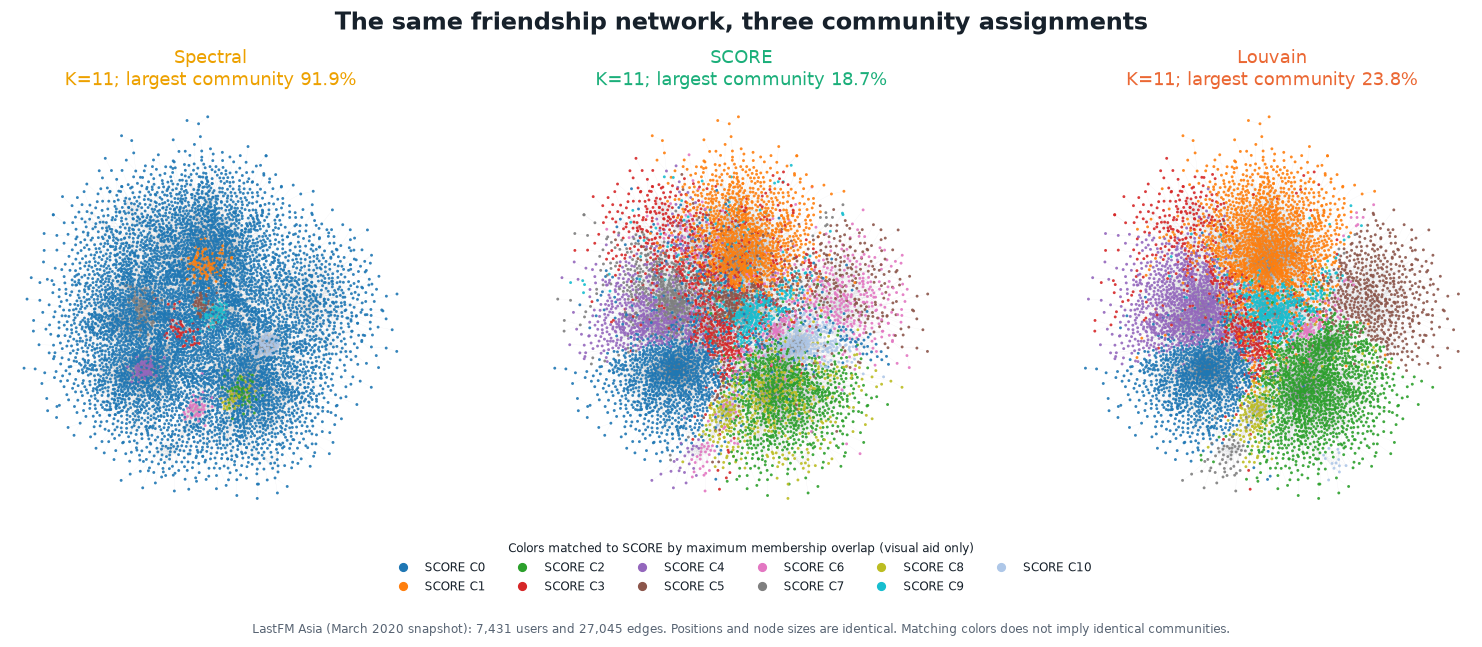

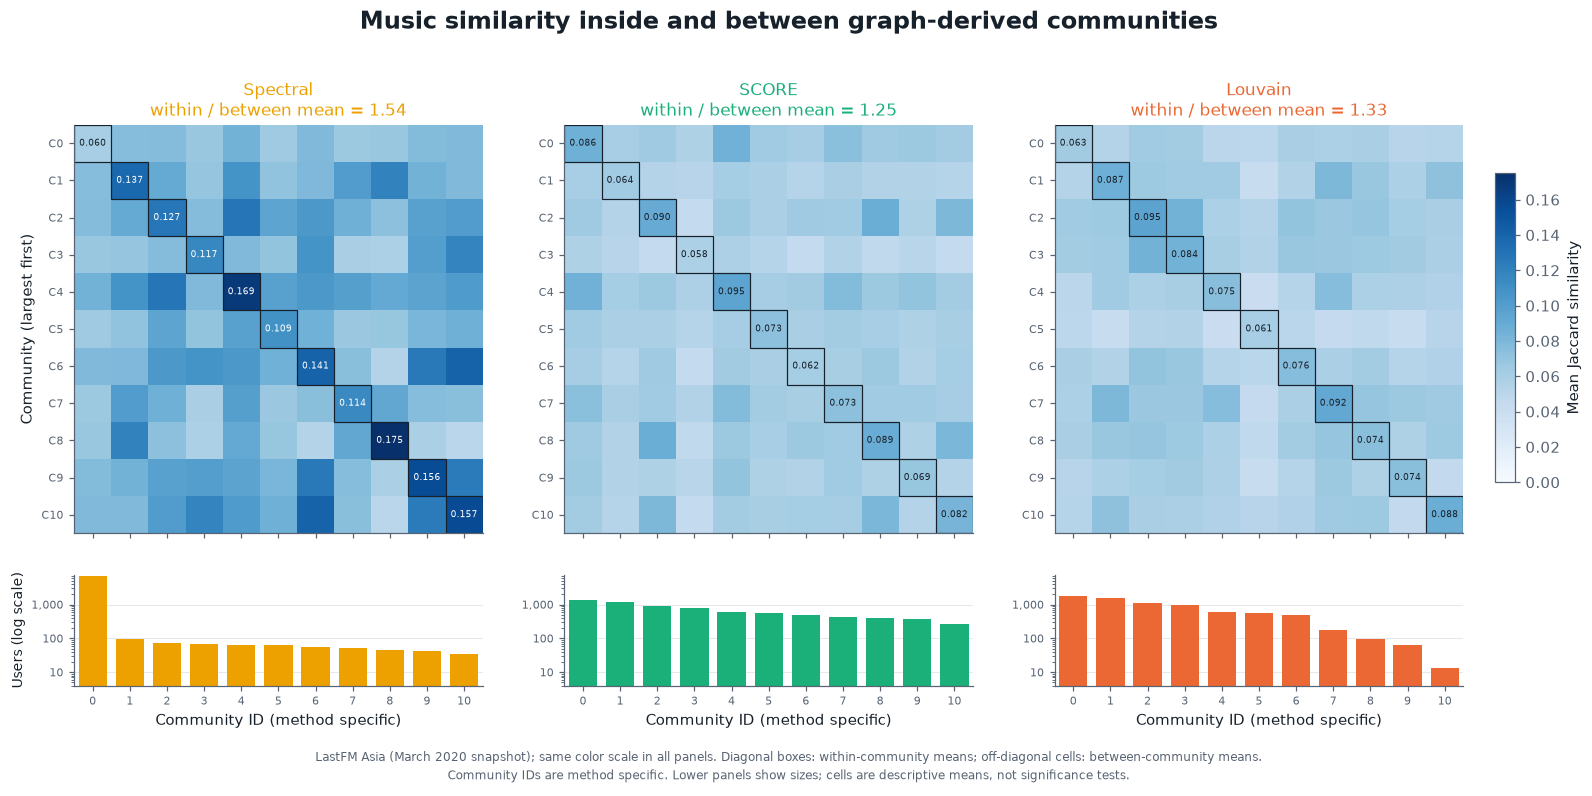

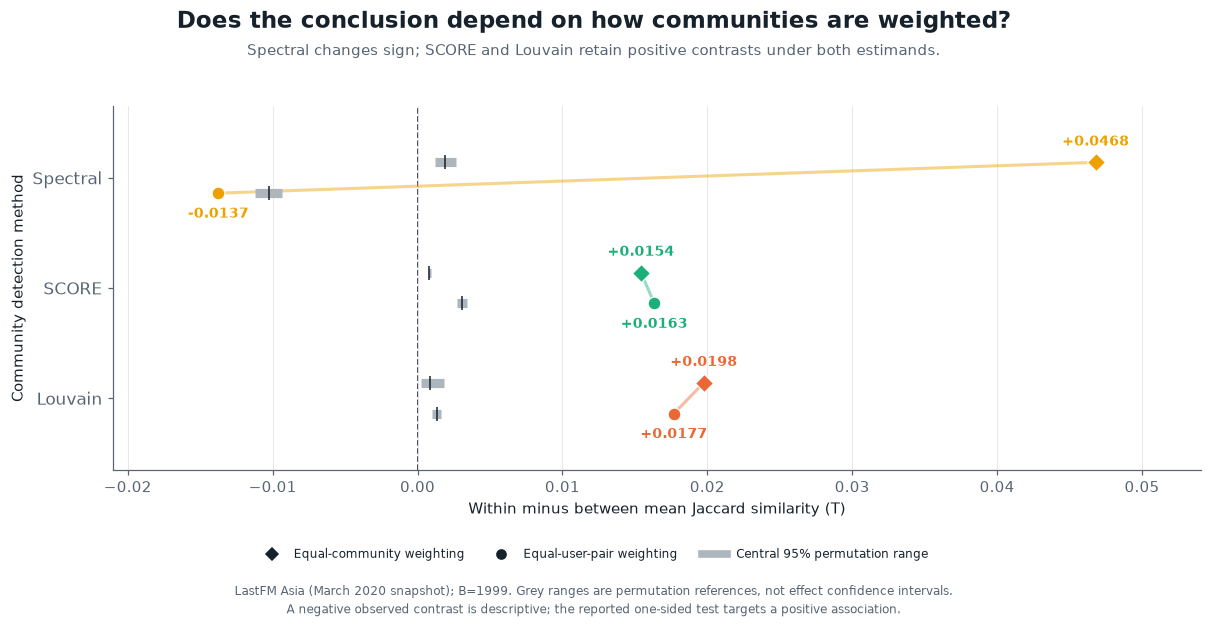

In [34]:
from visualizations import generate_figures
visualization_manifest = generate_figures(PROJECT_ROOT, run_root=RUN_ROOT, similarity=S,
                                         adjacency=A, nodes=nodes, show=True)
plt.show()
print('Exported: fig11_core_networks, fig12_core_music_heatmaps, fig13_weighting_sensitivity (PNG and PDF).')
print('Six-page review: figures/visualization_review.pdf; guide: tables/tab22_visualization_guide.csv')

## Appendix D. Targeted validation of the original three-method comparison
These additions address inference calibration, nuisance adjustment, recovery fairness, and algorithmic stability. They were specified after the earlier analysis was inspected and remain exploratory. They preserve the original primary reference and hypothesis family; no reference is selected by its p-value.

### D.1 Primary-reference sensitivity
Compare prespecified degree/activity quantile bin counts 3, 5, 7, and 10, plus exact degree crossed with activity quintiles. The original q5 draws are reused. Report reference-centered contrasts, Monte Carlo uncertainty, randomization support, and residual covariate association. Exact degree still only approximately adjusts for activity. Residual association alone neither proves nor disproves music exchangeability.

In [35]:
import statistical_validation as validation
from dataclasses import asdict
validation_config = validation.ValidationConfig.for_profile(PROFILE)
bin_validation, bin_support = validation.primary_binning_sensitivity(
    S, deg, n_art, partitions, TAB_DIR, OUT_DIR, validation_config, main_res)
display(bin_validation[['scheme','method','statistic','T','excess_T','p','p_Holm_3_methods_within_scheme_statistic']])
display(bin_support)

Primary bin sensitivity: degree_activity_q3
Primary bin sensitivity: degree_activity_q5
Primary bin sensitivity: degree_activity_q7
Primary bin sensitivity: degree_activity_q10
Primary bin sensitivity: degree_exact_activity_q5


,scheme,method,statistic,T,excess_T,p,p_Holm_3_methods_within_scheme_statistic
0,degree_activity_q3,Spectral,equal,0.046802,0.045215,0.0020,0.0060
1,degree_activity_q3,Spectral,pair,-0.013746,-0.003424,1.0000,1.0000
2,degree_activity_q3,SCORE,equal,0.015421,0.014752,0.0020,0.0060
3,degree_activity_q3,SCORE,pair,0.016337,0.013514,0.0020,0.0060
4,degree_activity_q3,Louvain,equal,0.019757,0.018883,0.0020,0.0060
5,degree_activity_q3,Louvain,pair,0.017688,0.016475,0.0020,0.0060
6,degree_activity_q5,Spectral,equal,0.046802,0.044918,0.0005,0.0015
7,degree_activity_q5,Spectral,pair,-0.013746,-0.003471,1.0000,1.0000
8,degree_activity_q5,SCORE,equal,0.015421,0.014623,0.0005,0.0015
9,degree_activity_q5,SCORE,pair,0.016337,0.013274,0.0005,0.0015


,scheme,method,occupied_strata,min_size,median_size,fraction_users_in_cells_below_10,expected_labels_changed,residual_log_degree_fraction,residual_log_activity_fraction
0,degree_activity_q3,Spectral,9,511,781.0,0.000000,0.138158,0.266264,0.000425
1,degree_activity_q3,SCORE,9,511,781.0,0.000000,0.877164,0.006335,0.001186
2,degree_activity_q3,Louvain,9,511,781.0,0.000000,0.831370,0.003792,0.002646
3,degree_activity_q5,Spectral,20,125,283.0,0.000000,0.125514,0.116817,0.000436
4,degree_activity_q5,SCORE,20,125,283.0,0.000000,0.874625,0.003442,0.001267
5,degree_activity_q5,Louvain,20,125,283.0,0.000000,0.828291,0.001468,0.004676
6,degree_activity_q7,Spectral,42,33,134.0,0.000000,0.118419,0.094058,0.000221
7,degree_activity_q7,SCORE,42,33,134.0,0.000000,0.871416,0.002890,0.000478
8,degree_activity_q7,Louvain,42,33,134.0,0.000000,0.824737,0.000938,0.002795
9,degree_activity_q10,Spectral,80,11,68.0,0.000000,0.114127,0.058640,0.000207


### D.2 Calibration of the actual primary procedure
Hold one independently generated network and its graph-only partitions fixed, then draw 200 independent music datasets per scenario. Each dataset uses 199 inner permutations, all three methods, and both weighting schemes. The invariant binned null has degree-bin-specific music preferences but no within-bin community effect; both references are invariant. A continuous-degree-only stress scenario has smooth degree-dependent music preferences and no additional community term: exact-degree permutations are invariant, whereas coarse q5 bins need not be. A planted community/music association is a positive control for power.

Use exact binomial Monte Carlo intervals, and a simultaneous lower bound over the 18 invariant-null cases to flag clear excess size. Also report family rejection after Holm correction over the three equal-community tests. These experiments condition on one generated graph and cannot establish exchangeability in LastFM. Stress rejection under approximate bins is not exact-null type I error.

In [36]:
primary_calibration, primary_calibration_family, calibration_design = validation.calibrate_primary_test(
    TAB_DIR, OUT_DIR, validation_config)
display(primary_calibration)
display(primary_calibration_family)

Calibration: exact_binned_null 50 / 200
Calibration: exact_binned_null 100 / 200
Calibration: exact_binned_null 150 / 200
Calibration: exact_binned_null 200 / 200
Calibration: smooth_degree_only_stress 50 / 200
Calibration: smooth_degree_only_stress 100 / 200
Calibration: smooth_degree_only_stress 150 / 200
Calibration: smooth_degree_only_stress 200 / 200
Calibration: planted_music_positive_control 50 / 200
Calibration: planted_music_positive_control 100 / 200
Calibration: planted_music_positive_control 150 / 200
Calibration: planted_music_positive_control 200 / 200


,scenario,scheme,method,statistic,replications,inner_permutations,alpha,rejection_count,rejection_fraction,pointwise_MC_low,pointwise_MC_high,assumed_invariant_null,interpretation,simultaneous_MC_lower,evidence_excess_size
0,exact_binned_null,degree_activity_q5,Spectral,equal,200,199,0.05,10,0.050,0.024234,0.090028,True,type_I_error,0.015715,False
1,exact_binned_null,degree_activity_q5,Spectral,pair,200,199,0.05,11,0.055,0.027772,0.096278,True,type_I_error,0.018503,False
2,exact_binned_null,degree_activity_q5,SCORE,equal,200,199,0.05,4,0.020,0.005476,0.050414,True,type_I_error,0.002360,False
3,exact_binned_null,degree_activity_q5,SCORE,pair,200,199,0.05,4,0.020,0.005476,0.050414,True,type_I_error,0.002360,False
4,exact_binned_null,degree_activity_q5,Louvain,equal,200,199,0.05,7,0.035,0.014186,0.070781,True,type_I_error,0.008145,False
5,exact_binned_null,degree_activity_q5,Louvain,pair,200,199,0.05,8,0.040,0.017425,0.077292,True,type_I_error,0.010516,False
6,exact_binned_null,degree_exact_activity_q5,Spectral,equal,200,199,0.05,8,0.040,0.017425,0.077292,True,type_I_error,0.010516,False
7,exact_binned_null,degree_exact_activity_q5,Spectral,pair,200,199,0.05,13,0.065,0.035061,0.108587,True,type_I_error,0.024380,False
8,exact_binned_null,degree_exact_activity_q5,SCORE,equal,200,199,0.05,6,0.030,0.011087,0.064151,True,type_I_error,0.005965,False
9,exact_binned_null,degree_exact_activity_q5,SCORE,pair,200,199,0.05,7,0.035,0.014186,0.070781,True,type_I_error,0.008145,False


,scenario,scheme,replications,family_size,Holm_family_rejection_fraction,pointwise_MC_low,pointwise_MC_high,assumed_invariant_null
0,exact_binned_null,degree_activity_q5,200,3,0.025,0.008166,0.057374,True
1,exact_binned_null,degree_exact_activity_q5,200,3,0.015,0.003104,0.043208,True
2,smooth_degree_only_stress,degree_activity_q5,200,3,0.170,0.120696,0.229372,False
3,smooth_degree_only_stress,degree_exact_activity_q5,200,3,0.060,0.031384,0.102462,True
4,planted_music_positive_control,degree_activity_q5,200,3,1.000,0.981725,1.000000,False
5,planted_music_positive_control,degree_exact_activity_q5,200,3,1.000,0.981725,1.000000,False


### D.3 Independent planted networks with matched K information
Use an independently specified balanced Bernoulli DCBM with three groups, 600 vertices, expected full-graph mean degree 18, degree heterogeneity sd in {0, 1.2}, and within/between intensity ratio in {3, 8}. Degree weights have block mean one and bounds [0.35, 2.5]. Edge probabilities are validated and never clipped. Thirty independent replications share truth and uniform edge draws across regimes within a replication. All four regimes use the same iteratively selected connected evaluation population; no graph is redrawn. Record retention to expose conditioning on this population.

Spectral and SCORE receive the planted K. Louvain receives the same K information through a prespecified resolution grid, choosing the first exact cluster-count match, otherwise the closest count. It never receives planted memberships. Fixed-resolution Louvain remains a separately marked reference. Report paired recovery differences and the paired heterogeneity interaction (SCORE minus Spectral in heterogeneous minus homogeneous networks). Intervals quantify Monte Carlo precision under this design, not population-network uncertainty or universal rankings.

In [37]:
independent_summary, independent_paired, degree_interaction = validation.independent_recovery(
    TAB_DIR, validation_config)
display(independent_summary)
display(independent_paired)
display(degree_interaction)

Independent recovery: 5 / 30
Independent recovery: 10 / 30
Independent recovery: 15 / 30
Independent recovery: 20 / 30
Independent recovery: 25 / 30
Independent recovery: 30 / 30


,setting,method,information_regime,replications,mean_estimated_K,K_match_fraction,mean_retained_fraction,NMI_mean,NMI_sd,NMI_mcse,NMI_ci_low,NMI_ci_high,ARI_mean,ARI_sd,ARI_mcse,ARI_ci_low,ARI_ci_high
0,degree_sd=0; within/between=3,Spectral,known_K_assisted,30,3.000000,1.000000,0.998833,0.666863,0.046491,0.008488,0.649503,0.684223,0.739930,0.044475,0.008120,0.723323,0.756537
1,degree_sd=0; within/between=3,SCORE,known_K_assisted,30,3.000000,1.000000,0.998833,0.668799,0.047448,0.008663,0.651081,0.686516,0.742156,0.045576,0.008321,0.725137,0.759174
2,degree_sd=0; within/between=3,Louvain,known_K_assisted,30,3.066667,0.866667,0.998833,0.542280,0.220199,0.040203,0.460057,0.624504,0.584652,0.248968,0.045455,0.491686,0.677618
3,degree_sd=0; within/between=3,Louvain (fixed resolution),fixed_resolution_reference,30,1.000000,0.000000,0.998833,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,degree_sd=0; within/between=8,Spectral,known_K_assisted,30,3.000000,1.000000,0.998833,0.994580,0.006493,0.001185,0.992155,0.997004,0.997162,0.003399,0.000621,0.995892,0.998431
5,degree_sd=0; within/between=8,SCORE,known_K_assisted,30,3.000000,1.000000,0.998833,0.994579,0.006493,0.001186,0.992154,0.997004,0.997161,0.003400,0.000621,0.995892,0.998431
6,degree_sd=0; within/between=8,Louvain,known_K_assisted,30,3.000000,1.000000,0.998833,0.997450,0.004981,0.000909,0.995590,0.999310,0.998665,0.002608,0.000476,0.997691,0.999639
7,degree_sd=0; within/between=8,Louvain (fixed resolution),fixed_resolution_reference,30,1.000000,0.000000,0.998833,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,degree_sd=1.2; within/between=3,Spectral,known_K_assisted,30,3.000000,1.000000,0.998833,0.290446,0.018136,0.003311,0.283673,0.297218,0.091448,0.014940,0.002728,0.085869,0.097027
9,degree_sd=1.2; within/between=3,SCORE,known_K_assisted,30,3.000000,1.000000,0.998833,0.520512,0.036767,0.006713,0.506782,0.534241,0.594670,0.038910,0.007104,0.580141,0.609199


,setting,metric,comparison,mean,sd,mcse,ci_low,ci_high,replications
0,degree_sd=0; within/between=3,NMI,SCORE minus Spectral,1.935552e-03,0.009744,0.001779,-0.001703,0.005574,30
1,degree_sd=0; within/between=3,NMI,Louvain minus SCORE,-1.265185e-01,0.200271,0.036564,-0.201301,-0.051736,30
2,degree_sd=0; within/between=3,NMI,Louvain minus Spectral,-1.245829e-01,0.200890,0.036677,-0.199597,-0.049569,30
3,degree_sd=0; within/between=3,ARI,SCORE minus Spectral,2.225501e-03,0.010168,0.001856,-0.001571,0.006022,30
4,degree_sd=0; within/between=3,ARI,Louvain minus SCORE,-1.575040e-01,0.229005,0.041810,-0.243016,-0.071992,30
5,degree_sd=0; within/between=3,ARI,Louvain minus Spectral,-1.552785e-01,0.230251,0.042038,-0.241256,-0.069301,30
6,degree_sd=0; within/between=8,NMI,SCORE minus Spectral,-4.064775e-07,0.003552,0.000649,-0.001327,0.001326,30
7,degree_sd=0; within/between=8,NMI,Louvain minus SCORE,2.871095e-03,0.006230,0.001137,0.000545,0.005197,30
8,degree_sd=0; within/between=8,NMI,Louvain minus Spectral,2.870689e-03,0.005701,0.001041,0.000742,0.005000,30
9,degree_sd=0; within/between=8,ARI,SCORE minus Spectral,-1.377142e-07,0.001860,0.000340,-0.000695,0.000694,30


,within_between_ratio,metric,contrast,mean,sd,mcse,ci_low,ci_high,replications
0,3.0,NMI,(SCORE minus Spectral) heterogeneous minus hom...,0.228130,0.040860,0.007460,0.212873,0.243388,30
1,3.0,ARI,(SCORE minus Spectral) heterogeneous minus hom...,0.500996,0.042130,0.007692,0.485265,0.516728,30
2,8.0,NMI,(SCORE minus Spectral) heterogeneous minus hom...,0.561093,0.025274,0.004614,0.551656,0.570531,30
3,8.0,ARI,(SCORE minus Spectral) heterogeneous minus hom...,0.809363,0.020210,0.003690,0.801817,0.816910,30


### D.4 Equal K information on the original calibrated generators
Reproduce the original Poissonized graphs exactly and verify retained sample sizes, edge counts, and original-method recovery against Appendix A. Add K-assisted Louvain on those identical graphs, reporting actual K-match rates. A finite grid need not attain K in every graph. Keep fixed-resolution Louvain separately visible. Generator calibration to fitted partitions and component selection remain limitations even after information is made comparable.

In [38]:
matched_legacy_summary, matched_legacy_paired = validation.legacy_matched_recovery(
    A, partitions, deg, TAB_DIR, validation_config, resolution=GAMMA)
display(matched_legacy_summary)
display(matched_legacy_paired)

Matched legacy recovery: Poisson DCBM: truncated SCORE+ truth 20 replicates
Matched legacy recovery: Poisson DCBM: Louvain truth 20 replicates
Matched legacy recovery: Homogeneous blocks: truncated SCORE+ truth 20 replicates


,setting,method,information_regime,replications,mean_estimated_K,K_match_fraction,mean_retained_fraction,NMI_mean,NMI_sd,NMI_mcse,NMI_ci_low,NMI_ci_high,ARI_mean,ARI_sd,ARI_mcse,ARI_ci_low,ARI_ci_high
0,Poisson DCBM: truncated SCORE+ truth,Spectral,known_K_assisted,20,11.00,1.00,0.884403,0.250386,0.007512,0.001680,0.246870,0.253901,0.027609,0.002897,0.000648,0.026253,0.028965
1,Poisson DCBM: truncated SCORE+ truth,SCORE,known_K_assisted,20,11.00,1.00,0.884403,0.727955,0.019187,0.004290,0.718975,0.736935,0.687820,0.047821,0.010693,0.665439,0.710201
2,Poisson DCBM: truncated SCORE+ truth,Louvain,known_K_assisted,20,10.80,0.40,0.884403,0.851369,0.008587,0.001920,0.847350,0.855387,0.823799,0.020423,0.004567,0.814241,0.833358
3,Poisson DCBM: truncated SCORE+ truth,Louvain (fixed resolution),fixed_resolution_reference,20,6.00,0.00,0.884403,0.763254,0.036493,0.008160,0.746175,0.780333,0.654321,0.075196,0.016814,0.619129,0.689514
4,Poisson DCBM: Louvain truth,Spectral,known_K_assisted,20,11.00,1.00,0.885325,0.231484,0.009665,0.002161,0.226961,0.236007,0.019857,0.003345,0.000748,0.018291,0.021422
5,Poisson DCBM: Louvain truth,SCORE,known_K_assisted,20,11.00,1.00,0.885325,0.662604,0.040690,0.009099,0.643561,0.681647,0.556289,0.049414,0.011049,0.533163,0.579416
6,Poisson DCBM: Louvain truth,Louvain,known_K_assisted,20,11.00,1.00,0.885325,0.946754,0.006322,0.001414,0.943795,0.949713,0.961970,0.004801,0.001074,0.959723,0.964217
7,Poisson DCBM: Louvain truth,Louvain (fixed resolution),fixed_resolution_reference,20,9.35,0.15,0.885325,0.929558,0.028803,0.006440,0.916078,0.943038,0.929653,0.070879,0.015849,0.896480,0.962825
8,Homogeneous blocks: truncated SCORE+ truth,Spectral,known_K_assisted,20,11.00,1.00,0.998849,0.772232,0.026681,0.005966,0.759745,0.784719,0.648374,0.055680,0.012450,0.622315,0.674434
9,Homogeneous blocks: truncated SCORE+ truth,SCORE,known_K_assisted,20,11.00,1.00,0.998849,0.754788,0.018426,0.004120,0.746164,0.763411,0.669581,0.063287,0.014151,0.639962,0.699200


,setting,metric,comparison,mean,sd,mcse,ci_low,ci_high,replications
0,Poisson DCBM: truncated SCORE+ truth,NMI,SCORE minus Spectral,0.477569,0.018080,0.004043,0.469108,0.486031,20
1,Poisson DCBM: truncated SCORE+ truth,NMI,Louvain minus SCORE,0.123414,0.020562,0.004598,0.113791,0.133037,20
2,Poisson DCBM: truncated SCORE+ truth,NMI,Louvain minus Spectral,0.600983,0.011229,0.002511,0.595728,0.606238,20
3,Poisson DCBM: truncated SCORE+ truth,ARI,SCORE minus Spectral,0.660211,0.048333,0.010808,0.637590,0.682831,20
4,Poisson DCBM: truncated SCORE+ truth,ARI,Louvain minus SCORE,0.135979,0.053011,0.011854,0.111169,0.160790,20
5,Poisson DCBM: truncated SCORE+ truth,ARI,Louvain minus Spectral,0.796190,0.021259,0.004754,0.786241,0.806140,20
6,Poisson DCBM: Louvain truth,NMI,SCORE minus Spectral,0.431120,0.041773,0.009341,0.411570,0.450671,20
7,Poisson DCBM: Louvain truth,NMI,Louvain minus SCORE,0.284150,0.041995,0.009390,0.264495,0.303804,20
8,Poisson DCBM: Louvain truth,NMI,Louvain minus Spectral,0.715270,0.011268,0.002520,0.709997,0.720544,20
9,Poisson DCBM: Louvain truth,ARI,SCORE minus Spectral,0.536433,0.050332,0.011255,0.512877,0.559989,20


### D.5 Shared graph perturbations and random seeds
Use 20 common edge-retention masks (independent retention probability 0.9) for Spectral, SCORE, and Louvain. In every replicate, all methods fit and evaluate the same largest connected component, with original K/resolution and the same fitting seed. Compare partitions by NMI/ARI and recompute both music contrasts. Each contrast change subtracts the original partition's contrast restricted to these same retained users, separating population removal from reassignment. This is graph-perturbation sensitivity, not a resampling confidence interval for a population effect.

Separately vary 10 fitting seeds on the original graph. Report seed-to-original NMI, music contrasts, and pairwise seed similarity. Pairwise similarities are dependent and receive no iid-pair confidence interval.

In [39]:
core_perturbations, core_perturbation_summary, core_seed_runs, core_seed_summary = validation.core_stability(
    A, S, G, nodes, partitions, K_STAR, GAMMA, TAB_DIR, OUT_DIR, validation_config)
display(core_perturbation_summary)
display(core_seed_summary)

Shared edge perturbations: 5 / 20
Shared edge perturbations: 10 / 20
Shared edge perturbations: 15 / 20
Shared edge perturbations: 20 / 20


,method,perturbations,min_retained_fraction,max_retained_fraction,NMI_mean,NMI_sd,NMI_q025,NMI_q975,ARI_mean,ARI_sd,ARI_q025,ARI_q975,T_change_same_users_mean,T_change_same_users_sd,T_change_same_users_q025,T_change_same_users_q975,pair_T_change_same_users_mean,pair_T_change_same_users_sd,pair_T_change_same_users_q025,pair_T_change_same_users_q975
0,Spectral,20,0.966626,0.973893,0.877277,0.015964,0.840831,0.896971,0.929120,0.012487,0.900417,0.942893,0.000088,0.000556,-0.000915,0.001094,-0.000414,0.000347,-0.000995,0.000140
1,SCORE,20,0.966626,0.973893,0.759333,0.019816,0.729188,0.790541,0.758940,0.033904,0.705438,0.805578,0.000007,0.000830,-0.001298,0.001533,-0.000851,0.000896,-0.002732,0.000542
2,Louvain,20,0.966626,0.973893,0.881710,0.013951,0.855866,0.905948,0.902809,0.018320,0.859786,0.926076,-0.000005,0.002405,-0.001963,0.005795,-0.000436,0.000851,-0.002608,0.000516


,method,seeds,pairwise_comparisons,mean_pairwise_NMI,minimum_pairwise_NMI,interpretation
0,Spectral,10,45,0.980381,0.953704,Pairwise seed comparisons are dependent; no ii...
1,SCORE,10,45,0.980126,0.917091,Pairwise seed comparisons are dependent; no ii...
2,Louvain,10,45,0.925005,0.889176,Pairwise seed comparisons are dependent; no ii...


### D.6 Validation figures and provenance
Five figures show primary calibration, nuisance-stratification sensitivity, independent recovery, calibrated-generator K fairness, and core-method stability. Keep these diagnostics and their limitations alongside the main research findings when choosing report claims.

Five-page validation review: figures/statistical_validation_review.pdf
Validation interpretation warnings:
- Continuous-degree-only stress: Spectral/equal rejects in 33.0% of q5 runs versus 6.5% with exact degree. Interpret the primary result as a binned reference comparison, not exact continuous-covariate adjustment.
- The finite Louvain resolution grid did not attain target K in every graph (independent minimum setting-level match rate 86.7%; calibrated minimum setting-level match rate 30.0%). Equal K information does not ensure equal achieved K; retain actual match rates.


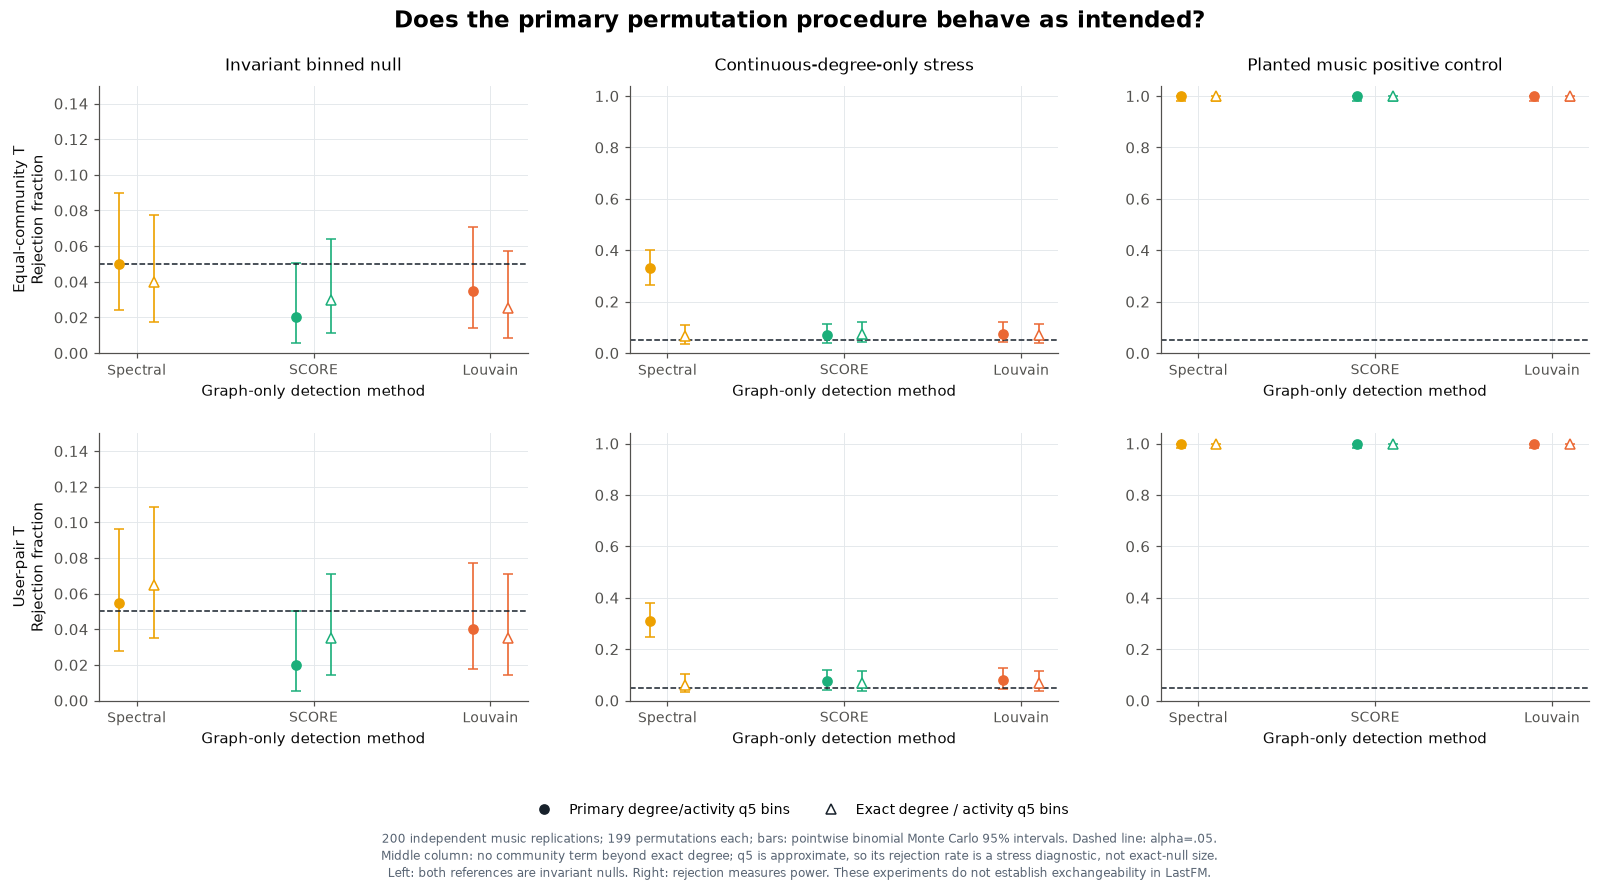

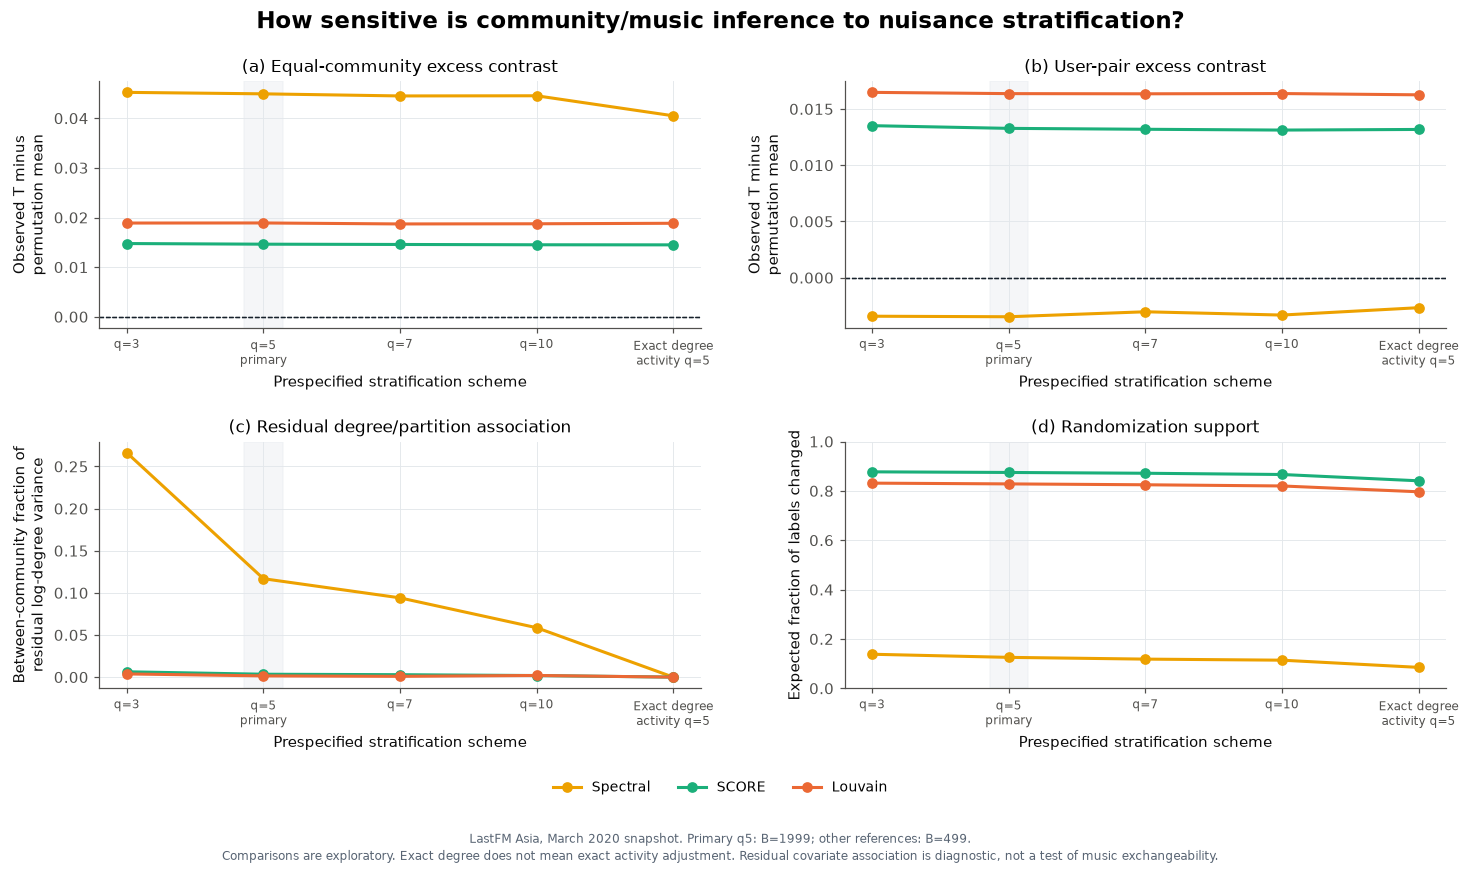

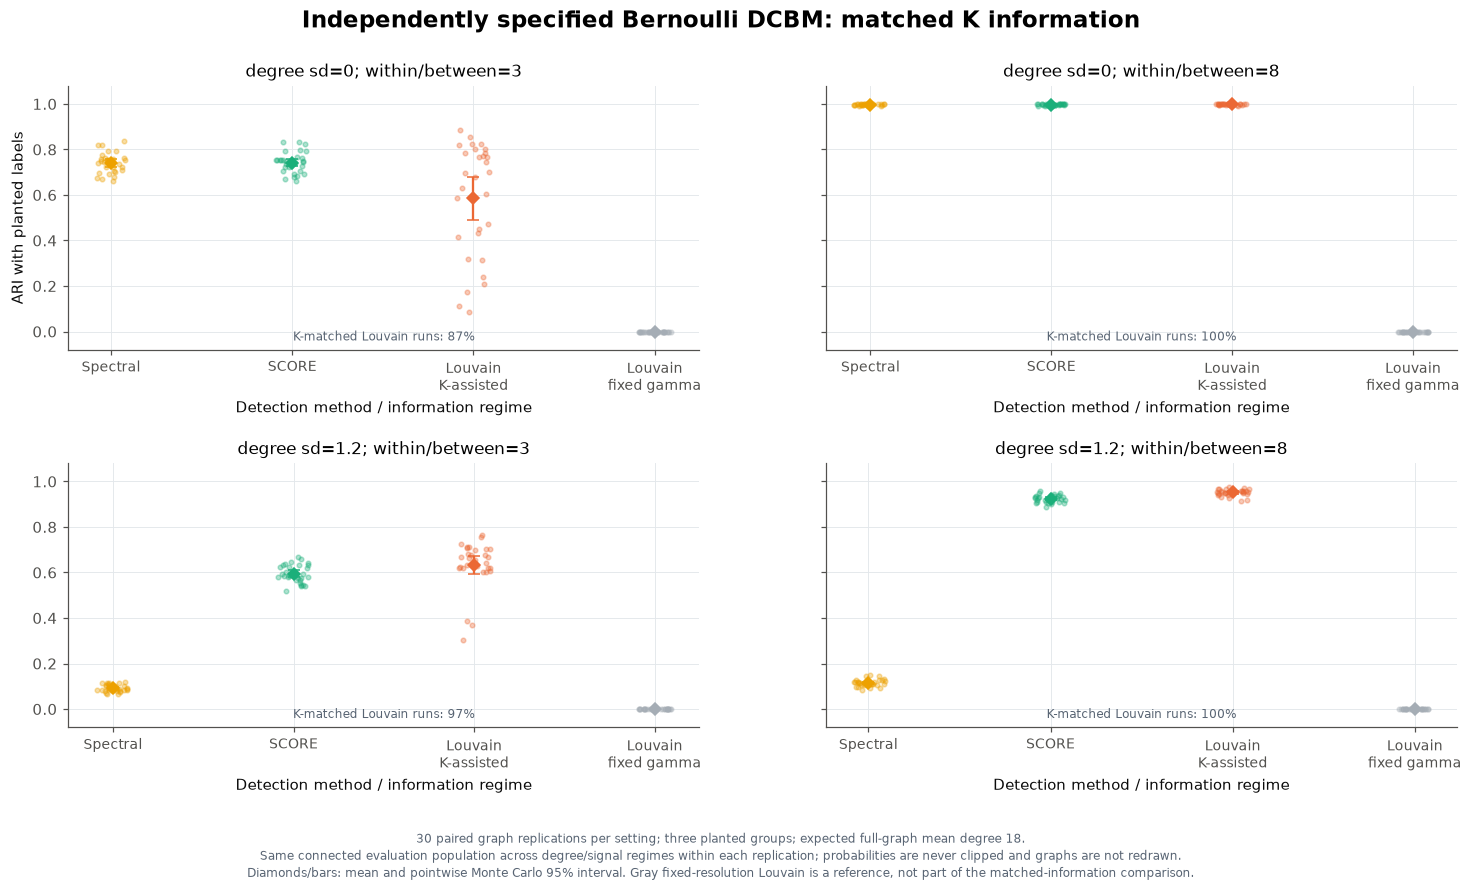

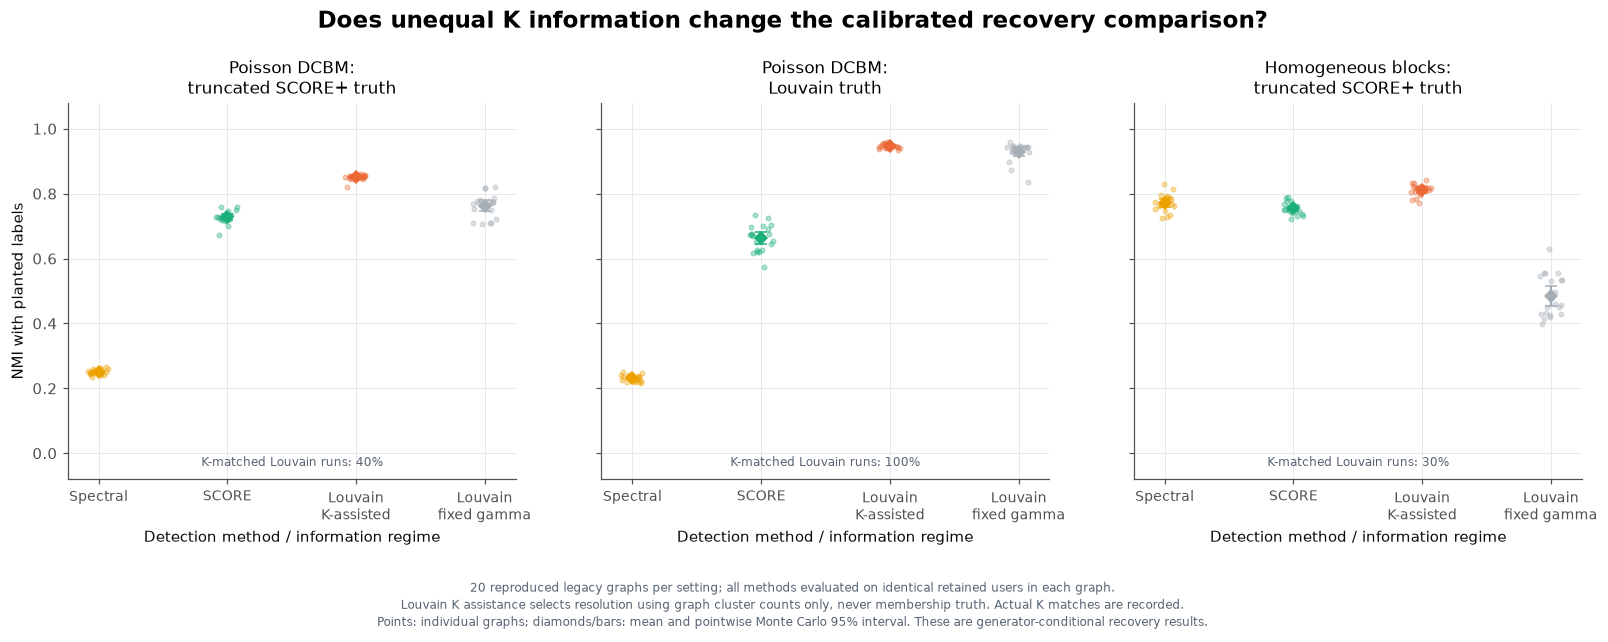

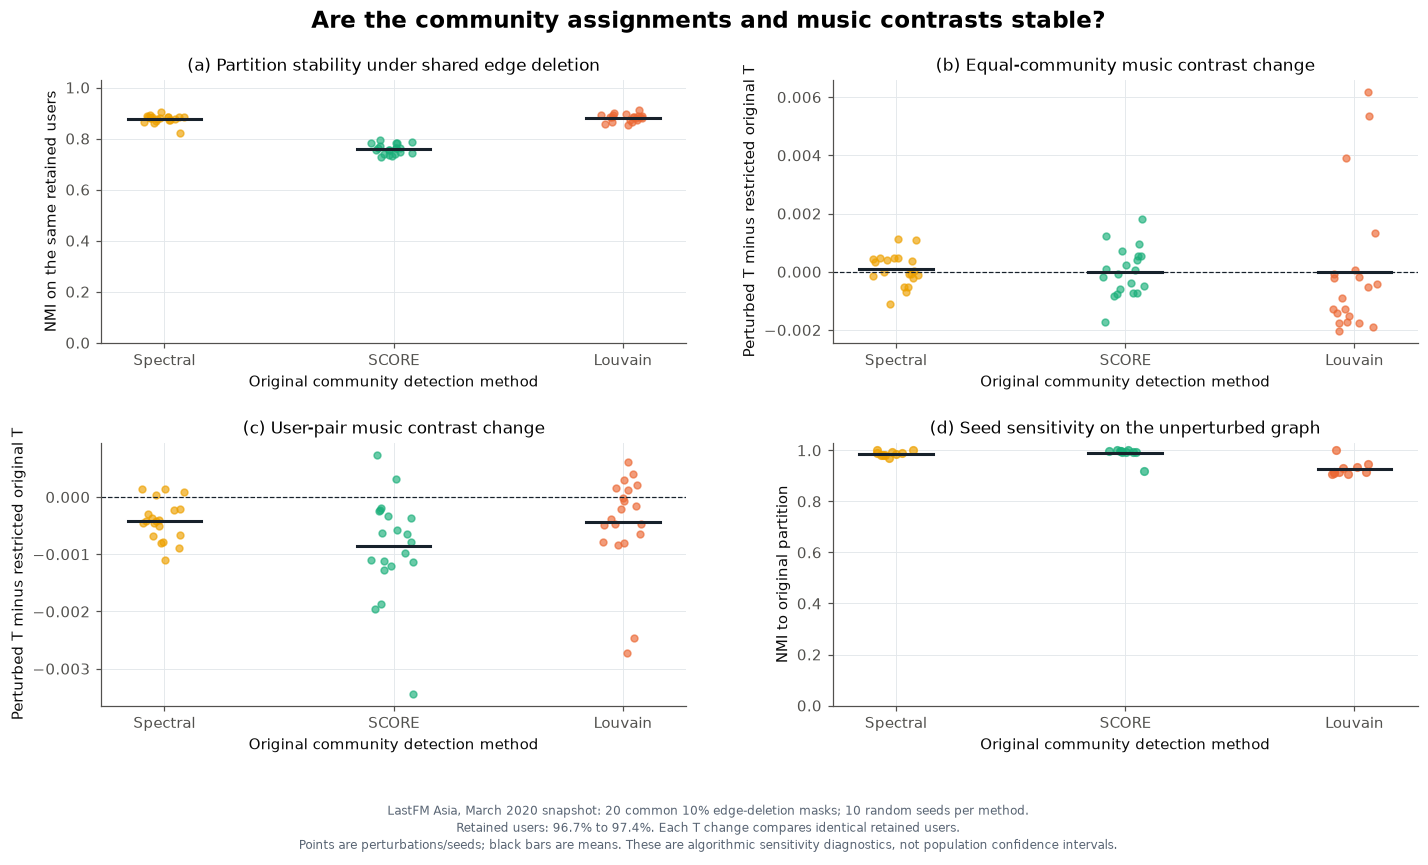

In [40]:
from validation_visualizations import generate_validation_figures, write_validation_manifest
validation_figures = generate_validation_figures(RUN_ROOT, show=True)
plt.show()
validation_manifest = write_validation_manifest(RUN_ROOT, validation_config, calibration_design, PROFILE)
print('Five-page validation review: figures/statistical_validation_review.pdf')
print('Validation interpretation warnings:')
for warning in validation_manifest['warnings']:
    print('-', warning)
if not validation_manifest['warnings']:
    print('No automatic diagnostic flag; observational exchangeability and model adequacy remain assumptions.')

## Appendix E. Report ingredients and reproducibility
The assignment recommends about eight main-text pages (12pt, single spacing), with code and extensive technical tables in supplementary material. The next cells map each rubric category to evidence, save exact configuration and file hashes, and generate current findings. They do not draft the report or guarantee a grade.

In [41]:
rubric_rows = [
    (10, 'Problem formulation and motivation', 'Question, target population, data appropriateness', 'Notebook opening and section 1; tab01, tab14', 'Define social graph versus external music outcome; qualify selected sample.'),
    (25, 'Methodology and technical understanding', 'Model, assumptions, algorithms, tuning, implementation', 'Sections 2-4; tab02-04, tab13, tab15, tab17-20, tab23-36; Appendix D', 'Explain DCBM geometry, sparse noise, ratio stabilization, graph-only tuning, estimands and invariant null.'),
    (25, 'Results and analysis', 'Complete comparisons, experiments, simulations, valid conclusions', 'Main: tab05, tab06, tab11, tab22 and fig06, fig11, fig12, fig13; extensions/sensitivity: tab08, tab16, tab19-21, tabA1-A3, tabB1-B2; tab23-37 and fig14-18', 'Report excess contrast, both weighting schemes, corrected p, MC precision, conditional recovery and exceptions.'),
    (15, 'Intellectual contribution and insight', 'Interpretation beyond mechanical implementation', 'Spectral versus SCORE degree correction, comparison with Louvain, weighting reversal; SCORE+ and country as supporting analyses', 'Explain when degree correction is insufficient and why effect size is not recovery accuracy.'),
    (10, 'Organization and clarity of the report', 'Logical exposition and understandable statistics', 'Figure/table selection saved below; technical details in notebook', 'Main narrative: follow-network communities -> independent music validation -> method-choice comparison -> extensions and sensitivity -> limitations.'),
    (5, 'Reproducibility and supporting materials', 'Data sources, software, choices, code', 'code/requirements-lock.txt, code/lastfm_stats.py, code/scripts/run_notebook.py, code/tests; outputs/run_manifest.json, permutation_nulls.npz', 'Provide Run All/full command, seeds, hashes, actual versions, raw nulls and raw simulations.'),
    (10, 'Webpage demonstration', 'Clear summary and communication', 'fig06, fig09, fig10; evidence JSON', 'Reuse verified findings later; webpage is outside this code-preparation task.'),
]
rubric = pd.DataFrame(rubric_rows, columns=['weight_percent', 'criterion', 'evidence_needed', 'available_material', 'writing_instruction'])
assert rubric.weight_percent.sum() == 100
savetab(rubric, 'tab00_report_rubric_evidence')

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

manifest = dict(run_started_utc=RUN_STARTED, run_finished_utc=datetime.now(timezone.utc).isoformat(), profile=PROFILE,
    configuration=dict(seed=SEED, B_MAIN=B_MAIN, B_ROBUST=B_ROBUST, N_SUB=N_SUB, N_SIM=N_SIM, N_INIT=N_INIT,
        K_candidates=list(K_RANGE), K_selected=K_STAR, tau=float(TAU), gamma=float(GAMMA), core_methods=CORE_METHODS, illustration_method=DETAIL_METHOD, B_COUNTRY=B_COUNTRY,
        statistical_validation=asdict(validation_config), primary_reference=PRIMARY_REFERENCE, primary_family_size=3, primary_statistic='equal', alternative='greater', alpha=.05,
        dtype='float64', analysis_status='exploratory reanalysis after prior inspection',
        python_threads=4, scoreplus_gap='1 - lambda_Kplus1/lambda_K <= 0.1',
        permutation_unit='entire user music records (implemented via inverse label permutations)'),
    data=dict(source=SRC, source_url='https://snap.stanford.edu/data/feather-lastfm-social.html',
        distribution_url='https://github.com/benedekrozemberczki/karateclub/tree/master/dataset',
        collection_period='March 2020 (SNAP description)', n=int(n), m=int(G.number_of_edges()), artist_count=int(X.shape[1])),
    versions={name:importlib.metadata.version(name) for name in ['numpy', 'scipy', 'pandas', 'networkx', 'scikit-learn', 'matplotlib', 'igraph', 'nbformat', 'ipython', 'threadpoolctl']},
    input_sha256={str(p.relative_to(PROJECT_ROOT)):file_hash(p) for p in sorted(Path(DATA_DIR).glob('*')) if p.is_file()},
    source_sha256={str(p):file_hash(PROJECT_ROOT / p) for p in [Path('code/lastfm_stats.py'), Path('code/visualizations.py'), Path('code/statistical_validation.py'), Path('code/validation_visualizations.py'), Path('code/scripts/run_validation.py'), Path('code/scripts/run_notebook.py'), Path('code/requirements.txt'), Path('code/requirements-lock.txt')]},
    notebook_cell_source_sha256=hashlib.sha256(''.join(cell.source for cell in __import__('nbformat').read(PROJECT_ROOT / 'code/STAT236_LastFM_Community_Music.ipynb', as_version=4).cells).encode()).hexdigest(),
    outputs=dict(figures=sorted(p.name for p in Path(FIG_DIR).glob('*') if p.is_file()),
        tables=sorted(p.name for p in Path(TAB_DIR).glob('*.csv'))))
Path(OUT_DIR, 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
primary = inference_tab[inference_tab.primary_family]
extension_results = inference_tab[inference_tab.strata.eq(PRIMARY_REFERENCE) & ~inference_tab.Method.isin(CORE_METHODS)]
evidence = dict(core_methods=CORE_METHODS, illustration_method=DETAIL_METHOD, B_COUNTRY=B_COUNTRY, n=int(n), m=int(G.number_of_edges()), K=int(K_STAR),
    research_question='Are users inside communities detected from the follow network more similar in music taste than users in different communities?',
    separate_information_sources=['follow network for community detection', 'music taste for external evaluation'],
    country_role='supplementary confounding check',
    primary_inference=primary.to_dict(orient='records'),
    method_extensions=extension_results.to_dict(orient='records'),
    all_primary_comparisons=primary.to_dict(orient='records'),
    simulation_summary=sim_tab.to_dict(orient='records'),
    calibration_summary=cal_summary,
    primary_calibration_summary=json.loads(primary_calibration.to_json(orient='records')),
    primary_calibration_family=json.loads(primary_calibration_family.to_json(orient='records')),
    independent_recovery_summary=json.loads(independent_summary.to_json(orient='records')),
    degree_correction_interaction=json.loads(degree_interaction.to_json(orient='records')),
    matched_legacy_summary=json.loads(matched_legacy_summary.to_json(orient='records')),
    core_perturbation_summary=json.loads(core_perturbation_summary.to_json(orient='records')),
    core_seed_summary=json.loads(core_seed_summary.to_json(orient='records')),
    validation_warnings=validation_manifest['warnings'],
    validation_review='figures/statistical_validation_review.pdf',
    validation_manifest='outputs/statistical_validation_manifest.json',
    implementation_diagnostics=pd.DataFrame(embedding_rows).to_dict(orient='records'),
    sensitivity_artifacts=['tab12_robustness.csv', 'tab19_joint_binning_sensitivity.csv', 'tab21_community_influence.csv'],
    main_text_figures=['fig11_core_networks', 'fig12_core_music_heatmaps', 'fig06_permutation_nulls', 'fig13_weighting_sensitivity'],
    figure_review='figures/visualization_review.pdf', figure_guide='tables/tab22_visualization_guide.csv',
    main_text_tables=['tab01_data_summary', 'tab06_main_test', 'tab11_method_comparison'],
    required_qualifications=['Exploratory, not preregistered.', 'Conditional exchangeability within coarse bins is an assumption.',
        'No causal decomposition of country and social effects.', 'MC intervals and permutation ranges are not population effect CIs.',
        'Truncated SCORE+ is a modified implementation.', 'Recovery rankings are conditional on the specified generators.'])
Path(OUT_DIR, 'report_evidence.json').write_text(json.dumps(evidence, indent=2))
display(rubric)

,weight_percent,criterion,evidence_needed,available_material,writing_instruction
0,10,Problem formulation and motivation,"Question, target population, data appropriateness","Notebook opening and section 1; tab01, tab14",Define social graph versus external music outc...
1,25,Methodology and technical understanding,"Model, assumptions, algorithms, tuning, implem...","Sections 2-4; tab02-04, tab13, tab15, tab17-20...","Explain DCBM geometry, sparse noise, ratio sta..."
2,25,Results and analysis,"Complete comparisons, experiments, simulations...","Main: tab05, tab06, tab11, tab22 and fig06, fi...","Report excess contrast, both weighting schemes..."
3,15,Intellectual contribution and insight,Interpretation beyond mechanical implementation,"Spectral versus SCORE degree correction, compa...",Explain when degree correction is insufficient...
4,10,Organization and clarity of the report,Logical exposition and understandable statistics,Figure/table selection saved below; technical ...,Main narrative: follow-network communities -> ...
5,5,Reproducibility and supporting materials,"Data sources, software, choices, code","code/requirements-lock.txt, code/lastfm_stats....","Provide Run All/full command, seeds, hashes, a..."
6,10,Webpage demonstration,Clear summary and communication,"fig06, fig09, fig10; evidence JSON",Reuse verified findings later; webpage is outs...


In [42]:
display(Markdown(f"""**Current run: {PROFILE}.** {n:,} users, {G.number_of_edges():,} edges; graph-selected K={K_STAR}.

**Research question:** communities are estimated from the follow network alone, then tested using music taste as a separate external source. The primary comparison is Spectral, SCORE and Louvain; country is supplementary.
"""))
for method in CORE_METHODS:
    result = primary[primary.Method.eq(method)].iloc[0]
    pair = main_res[method]['pair_result']
    display(Markdown(f"""**{method}:** within/between mean Jaccard ratio={result['ratio S_same/S_diff']:.3f};
equal-community T={result['T']:.5f}, degree/activity-null excess={result['excess_T']:.5f};
p={result['p']:.5g}, Holm p (original three-method family)={result['p_Holm_primary_3_methods']:.5g}.
Pair-weighted sensitivity T={pair['T']:.5f}.
"""))
display(Markdown("""SCORE+ implementations are documented extensions. Country-only and joint-country references are supplementary checks in Appendix B.
These are associations under stated permutation assumptions, not causal effects.
Main comparison: `tab06_main_test.csv` and `tab11_method_comparison.csv`; all references: `tab16_inference_all_references.csv`.
"""))
display(Markdown("**Targeted validation:** primary calibration and stratification sensitivity, matched-information recovery, and shared core-method perturbations are in Appendix D. Review these before choosing report claims."))
for warning in validation_manifest['warnings']:
    display(Markdown('**Qualification:** '+warning))


**Current run: full.** 7,431 users, 27,045 edges; graph-selected K=11.

**Research question:** communities are estimated from the follow network alone, then tested using music taste as a separate external source. The primary comparison is Spectral, SCORE and Louvain; country is supplementary.


**Spectral:** within/between mean Jaccard ratio=1.544;
equal-community T=0.04680, degree/activity-null excess=0.04492;
p=0.0005, Holm p (original three-method family)=0.0015.
Pair-weighted sensitivity T=-0.01375.


**SCORE:** within/between mean Jaccard ratio=1.253;
equal-community T=0.01542, degree/activity-null excess=0.01462;
p=0.0005, Holm p (original three-method family)=0.0015.
Pair-weighted sensitivity T=0.01634.


**Louvain:** within/between mean Jaccard ratio=1.334;
equal-community T=0.01976, degree/activity-null excess=0.01890;
p=0.0005, Holm p (original three-method family)=0.0015.
Pair-weighted sensitivity T=0.01769.


SCORE+ implementations are documented extensions. Country-only and joint-country references are supplementary checks in Appendix B.
These are associations under stated permutation assumptions, not causal effects.
Main comparison: `tab06_main_test.csv` and `tab11_method_comparison.csv`; all references: `tab16_inference_all_references.csv`.


**Targeted validation:** primary calibration and stratification sensitivity, matched-information recovery, and shared core-method perturbations are in Appendix D. Review these before choosing report claims.

**Qualification:** Continuous-degree-only stress: Spectral/equal rejects in 33.0% of q5 runs versus 6.5% with exact degree. Interpret the primary result as a binned reference comparison, not exact continuous-covariate adjustment.

**Qualification:** The finite Louvain resolution grid did not attain target K in every graph (independent minimum setting-level match rate 86.7%; calibrated minimum setting-level match rate 30.0%). Equal K information does not ensure equal achieved K; retain actual match rates.